# Task 2: 10-Word Speech Recognition 

## Introduction

### Aim

This project aims to create a speech recognition model using machine learning tools that can classify both different words spoken and the different speaker behind the word spoken.

## Methodology

### Data Description

The data analysed contains audio sample observations of 10 unique spoken words from 5 distinct speakers. The audio files are extracted from the Google Speech Commands Dataset (via a Kaggle dataset reference page). Each speaker recorded every word exactly 5 times, so each word has 25 recordings (5 speakers × 5 repetitions).

Although the files only contain audio information, the metadata variables (word and speaker) are deducible via file name and dataset folder structure, segmenting observations by words. These variables will be encoded as labels before training and testing the build model.

The total speech dataset contains 250 unique audio observations: 25 recordings for each of the 10 words, or 50 recordings per speaker.

Words chosen for the experiment:
- Zero (0)
- One (1)
- Two (2)
- Three (3)
- Four (4)
- Five (5)
- Six (6)
- Seven (7)
- Eight (8)
- Nine (9)

**No speaker overlap is allowed between different split samples!**

### Data Collection and Quality Control

The reason for the chosen word collection is reflective of the principle of proportionality between the requirements outlined and the computational capacity needed to search all possible word combinations.

A side script written in Python was executed to identify speakers who had at least five distinct recordings for a given word. Unique combinations of these speakers were then searched to identify groups with sufficient recordings across shared words. As some of the most complete words in the dataset were the number words, this process identified speakers who had recorded all ten number words, providing a consistent basis for the subsequent analysis.

Data collection flow chart:

<img src="data_collection.png" alt="alt text" title="Title" width="500">


### Used Tools

A Convolutional Neural Network (CNN) is selected for its ability to extract discriminative features from 2D spectrogram representations while providing an appropriate balance between classification performance and computational efficiency.

Python 3.14.5 is used for this task.

In accordance with the principle of proportionality, the architecture and depth of the CNN will be adapted to the available computational resources. The current model is trained on a laptop computer equipped with 32 GB of RAM and a GPU with 8 GB of dedicated VRAM. These resources will be considered when determining the model's complexity to ensure that the training process remains computationally feasible.

### Applied Methods

The grouping of samples into distinct datasets will not include replacement to not allow the possibility for duplicate observations. This will make the predictions of the algorithm bias.

 Each of the samples created will contain at all unique words, but no speaker overlap is allowed between training and test sets.  The division of the collected dataset is as the following:
- **Training dataset:** 200 observations (80% - all words for 4 unique speakers).
- **Testing dataset:** 50 observations (20% - all words for 1 unique speaker).

The training sample will be used to train the machine learning methods chosen for analysis and the testing dataset recognition results will be compared at the end.

Overall model performance will be evaluated on the following scoring metrics:
- **Accuracy of predictions;**
- **Precision of predictions;**
- **Recall of predictions.**

## 1. Dataset Preparation

### Dataset Loading and Inspection

Necessary libraries are loaded into the environment.

In [1]:
# Audio related libraries
import librosa
import glob
from pathlib import Path

# Data analysis related libraries
import numpy as np
import random

# Neural network libraries
import torch
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
import torchmetrics

# Visualisation libraries
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Custom functions
import speakreg

C:\Users\Lenovo\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Uniform colour map is declared so all outputs possess similar colour schemes.

Additional considerations for people possessing poor visibility were taken into account.

In [2]:
static_cmap = ["salmon", "skyblue"]
cmap = LinearSegmentedColormap.from_list("custom", ["#c6fcff", "#ffffff", "#FA8072"])

Dataset is loaded from the same directory where this script is located within the local machine. The original recordings are 1-second WAV files sampled at 16 000 Hz.

In [3]:
master_folder_path = Path(r"C:\Users\Lenovo\Desktop\vu_masters\1_semester\natural_language_and_speech_processing\6_assignments\task_2\recordings")

audio_dataset = []

numbers = ["zero", "one", "two", "three", "four",
           "five", "six", "seven", "eight", "nine"]

for sub_folder in master_folder_path.iterdir():
    if not sub_folder.is_dir() or sub_folder.name not in numbers:
        continue
    for file_path in sub_folder.glob("*.wav"):
        y, sr = librosa.load(file_path, sr=None)
        word = sub_folder.name
        speaker_id = str(file_path.name)[:8]
        audio_dataset.append([y, sr, word, speaker_id])
    print(f"Loaded and stored all recordings for the word: {sub_folder.name}")

Loaded and stored all recordings for the word: eight
Loaded and stored all recordings for the word: five
Loaded and stored all recordings for the word: four
Loaded and stored all recordings for the word: nine
Loaded and stored all recordings for the word: one
Loaded and stored all recordings for the word: seven
Loaded and stored all recordings for the word: six
Loaded and stored all recordings for the word: three
Loaded and stored all recordings for the word: two
Loaded and stored all recordings for the word: zero


Inspect the top 5 observations of the loaded dataset and overall shape

In [4]:
audio_dataset[:5]

[[array([0.05664062, 0.06750488, 0.07418823, ..., 0.06356812, 0.06756592,
         0.0680542 ], shape=(16000,), dtype=float32),
  16000,
  'eight',
  '179a61b7'],
 [array([-0.0012207 , -0.00158691, -0.00228882, ..., -0.00177002,
         -0.0010376 , -0.00137329], shape=(16000,), dtype=float32),
  16000,
  'eight',
  '179a61b7'],
 [array([-0.00601196, -0.00125122, -0.00076294, ...,  0.12033081,
          0.09085083,  0.06808472], shape=(16000,), dtype=float32),
  16000,
  'eight',
  '179a61b7'],
 [array([0.02209473, 0.03244019, 0.03887939, ..., 0.02511597, 0.02328491,
         0.02178955], shape=(16000,), dtype=float32),
  16000,
  'eight',
  '179a61b7'],
 [array([0.00082397, 0.00628662, 0.00942993, ..., 0.00524902, 0.00744629,
         0.00421143], shape=(16000,), dtype=float32),
  16000,
  'eight',
  '179a61b7']]

One example recording per word is played below.

In [5]:
speakreg.play_word_examples(audio_dataset, numbers)

zero


one


two


three


four


five


six


seven


eight


nine


Making sure all audio observations have the same sampling rate. Differing rates may impact quality of predictions when testing the Convolutional Neural Network.

Since every recording is loaded at its native rate, the check below confirms that all of them were recorded at the same rate of 16 000 Hz.

In [6]:
sr_benchmark = audio_dataset[0][1]

if all(track[1] == sr_benchmark for track in audio_dataset):
    print(f"All sample rates are the same at {sr_benchmark}Hz.")
else:
    print("All sample rates are not the same, try fixing sr when loading the data.")

All sample rates are the same at 16000Hz.


Same is checked for consistent signal duration. Recordings shorter than the longest one are zero-padded at the end to match its length.

In [7]:
max_samples = max(len(track[0]) for track in audio_dataset)
max_duration = max_samples / sr_benchmark

n_padded = 0
for track in audio_dataset:
    if len(track[0]) < max_samples:
        track[0] = librosa.util.fix_length(track[0], size=max_samples)
        n_padded += 1

if any(len(track[0]) != max_samples for track in audio_dataset):
    raise ValueError("Recordings still differ in length after padding.")

print(f"Padded {n_padded} recording(s); all recordings are now {round(max_duration, 3)} seconds ({max_samples} samples) long")

Padded 0 recording(s); all recordings are now 1.0 seconds (16000 samples) long


### Descriptive Statistics

Frequency domains are created when applying fourier transforms to time domain information (waveforms)

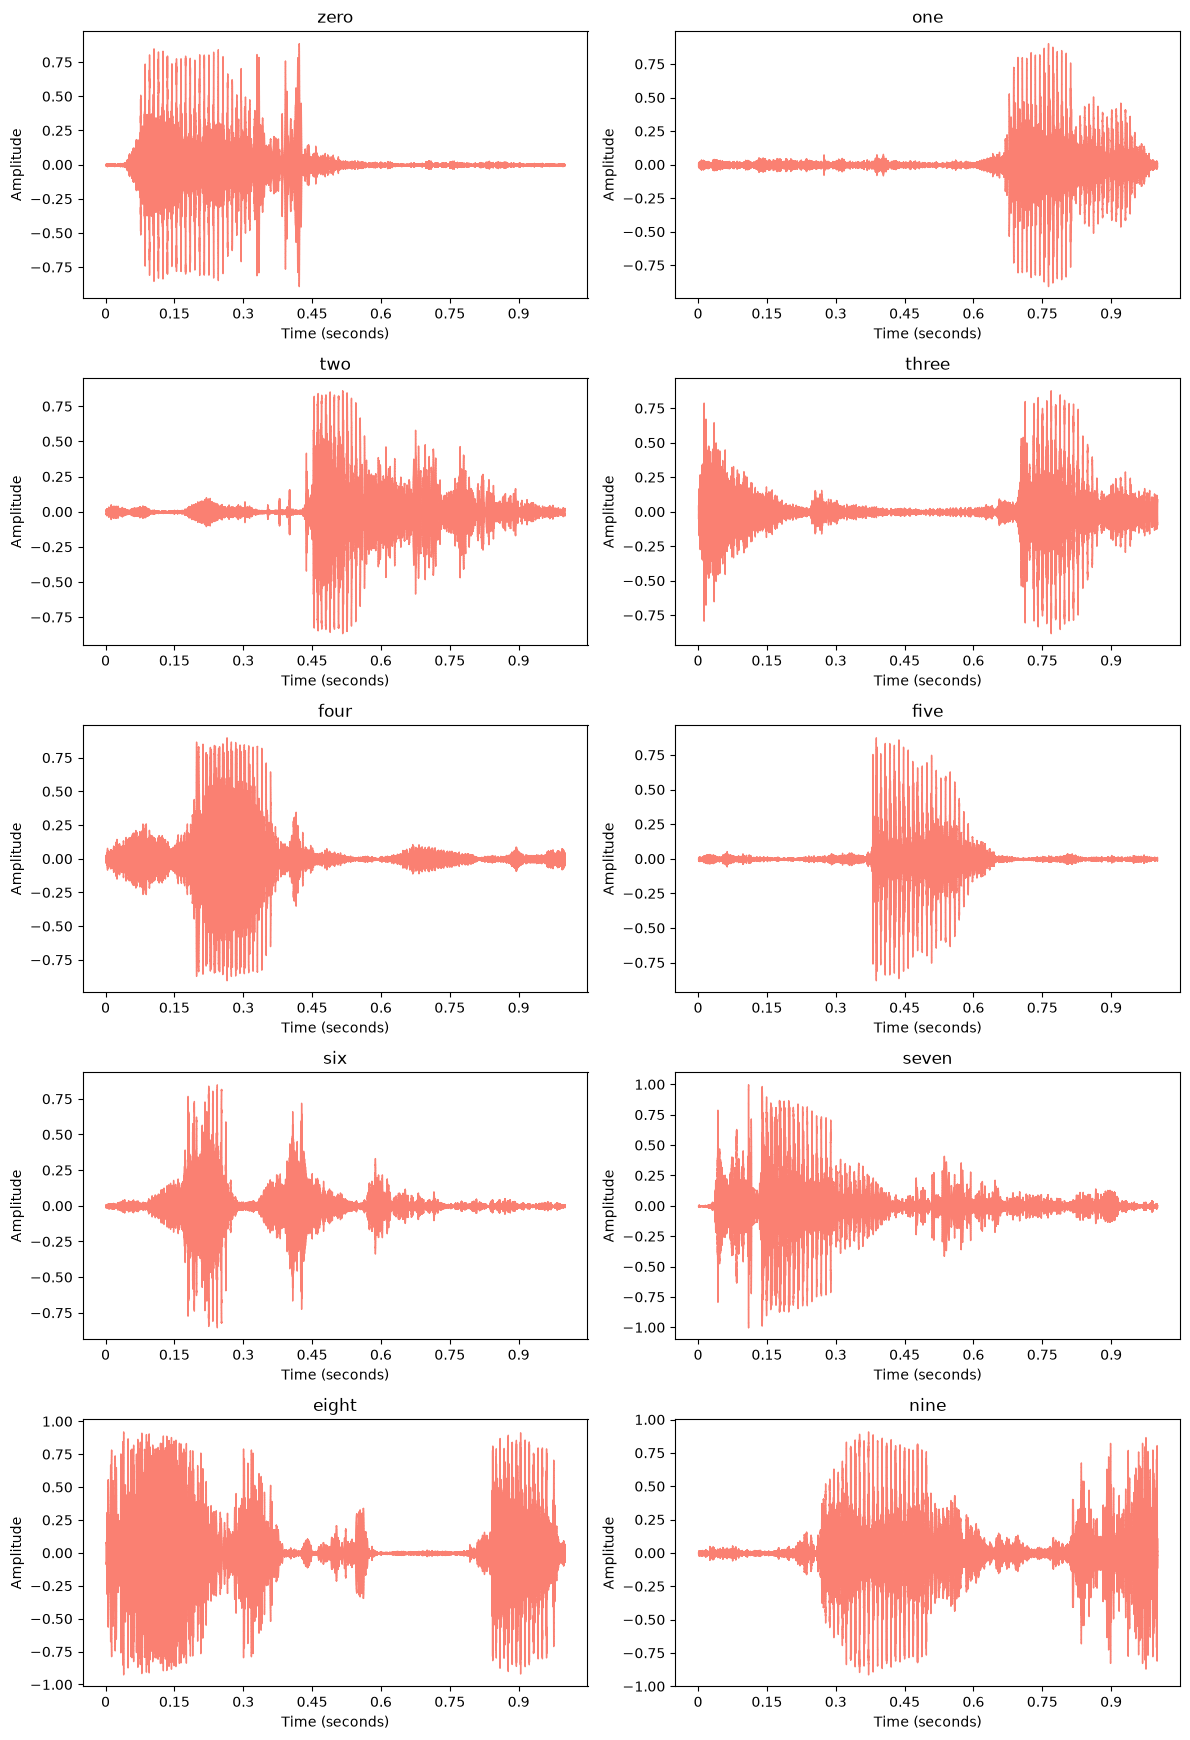

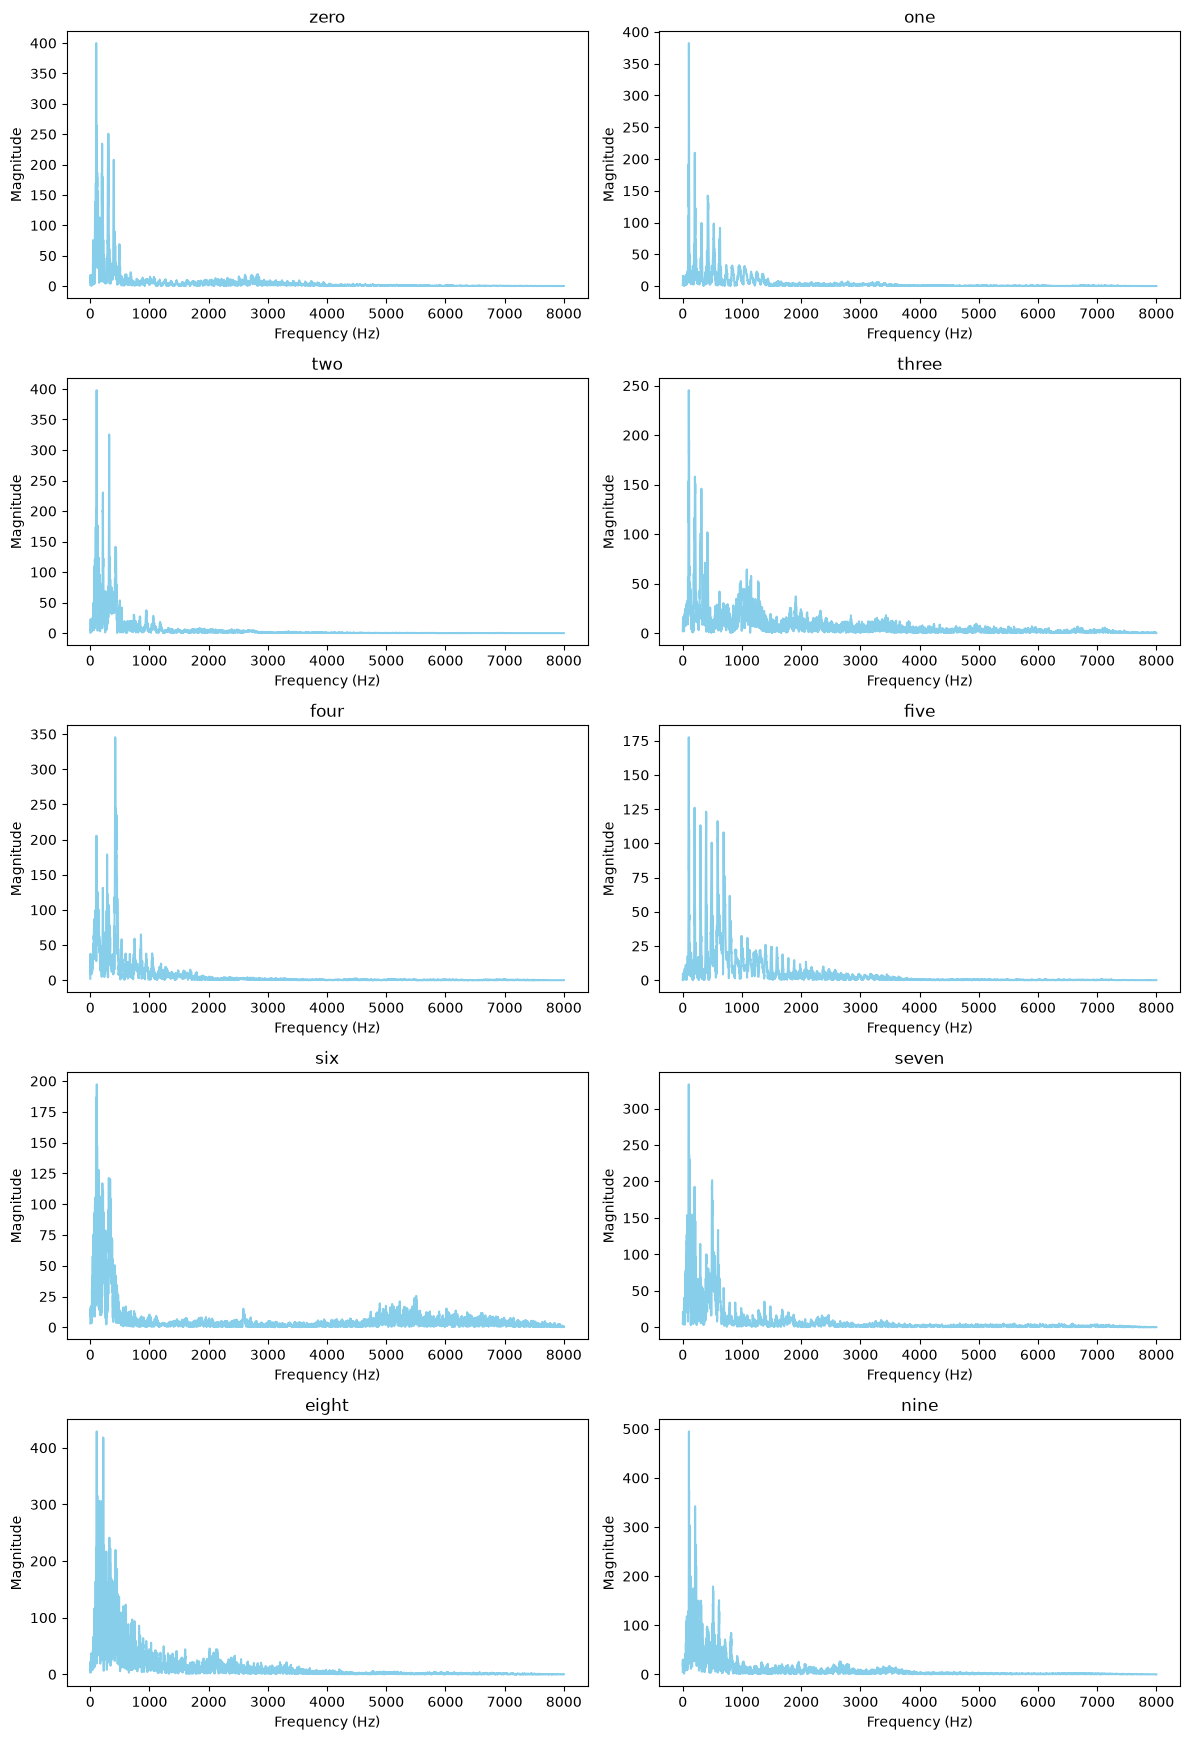

In [8]:
speakreg.plot_audio_analysis(audio_dataset, numbers, ["wave", "freq"], cmap, 2, colours=static_cmap)

### Dataset Cleaning

Quality assurance is applied to the following factors:
- all recordings are present (no missing observations);
- exactly five speakers are obtained;
- exactly 10 words collected, each spoken by every speaker exactly five times (25 recordings per word);
- all recordings have the same sample rate (sr);
- all recordings are the same length.

Given the small and custom sample size analysed, no individual observations need special treatment to be applied to be analyzed.

## 2. Feature Extraction

### Log-Mel Spectrogram Representation

Each recording is converted into a **log-mel spectrogram**, a 2D time–frequency image, which is used as the only input representation of the CNN.

The result is a fixed-size image in which each word appears as a pattern that is local in time and frequency. This is the kind of input a CNN is designed for, as its convolution filters detect local patterns wherever they occur in the image.

Feature extraction parameters:
- **Sampling frequency:** 16 000 Hz (Nyquist frequency 8 000 Hz)
- **Frame (window) length:** 25 ms
- **rame shift (hop length):** 10 ms
- **Window function:** Hann
- **FFT size:** 512 points (31.25 Hz apart)
- **Number of mel filters:** 64

**Dimensions of the feature representation:** a 1 s recording at a 10 ms frame shift gives **101 frames**, so each recording becomes a **64 × 101** matrix (mel bands × time frames), with values from −80 to 0 dB.

In [9]:
mel_params = {
    "win_length": 400,
    "hop_length": 160,
    "window": "hann",
    "n_fft": 512,
    "n_mels": 64,               
    "fmin": 0,
    "fmax": sr_benchmark // 2,
}

spectrogram_dataset = []
for signal, rate, word, speaker_id in audio_dataset:
    mel_spec_db = speakreg.log_mel_spectrogram(signal, rate, mel_params)
    spectrogram_dataset.append([mel_spec_db, rate, word, speaker_id])

The log-mel spectrogram of one recording of each word (the first one found for each word, all by speaker 179a61b7) is plotted below. Time runs along the x-axis, mel frequency along the y-axis, and the colour shows the level in dB relative to the loudest point of the recording.

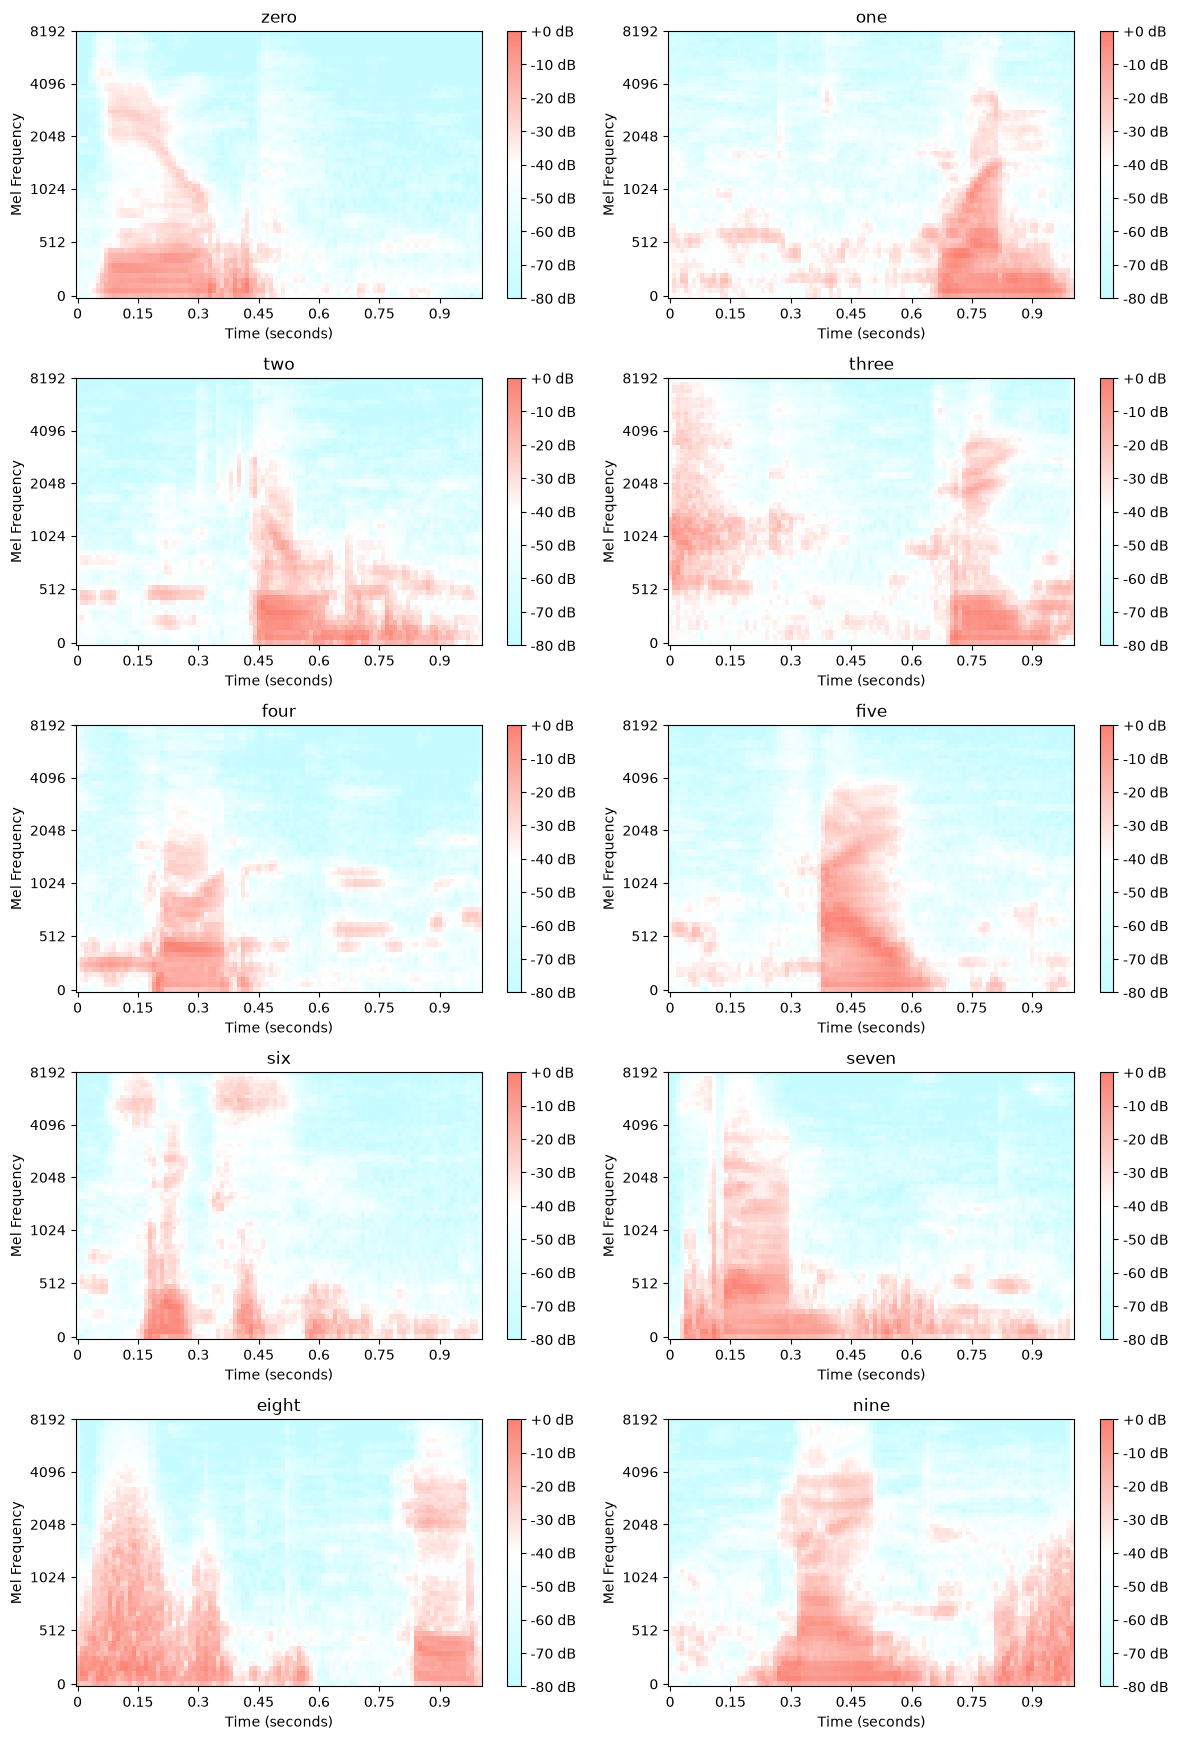

In [10]:
speakreg.plot_audio_analysis(spectrogram_dataset, numbers, ["spectro"], cmap, 2, mel_params=mel_params)

### Establishing Seed and Test Speakers

The dataset is segmented based on the word spoken being the dependent variable into training and test samples. A fixed seed is set for Python, NumPy and PyTorch so the test speaker, model initialisation and training order are the same on every run.

For as unbiased results as possible, the speaker represented in the test data is chosen at random.

In [11]:
gen_seed = 20260916
random.seed(gen_seed)
np.random.seed(gen_seed)
torch.manual_seed(gen_seed)

unique_values = sorted(set(row[3] for row in audio_dataset))
testing_speaker = np.random.choice(unique_values)
print(f"Test speaker: {testing_speaker}")

Test speaker: 21832144


Given the established training and testing data, the depedent and independent variables are separated.

Speaker ID and sample rate will not be used from now on since they have served their purpose.

### CNN Input Features

Each observation is fed to the CNN as a single-channel image: its log-mel spectrogram with an added channel axis, shaped (1, 64, 101) = (channels, mel bands, time frames). The values are standardised using training-set statistics only, so no information from the test speaker leaks into training. Words are encoded as class labels by their position in `numbers` (zero = 0, one = 1, ..., nine = 9).

#### Gathering per-recording feature images, labels and speakers

Each recording's log-mel spectrogram is converted to a PyTorch tensor with a leading channel axis, while the word label and speaker ID are collected alongside it.

In [12]:
batch_size = 16

images, labels, speakers = [], [], []

for mel_db, _, word, speaker in spectrogram_dataset:
    images.append(torch.from_numpy(mel_db).float()[None])  # add the channel axis: (1, mel bands, frames)
    labels.append(numbers.index(word))
    speakers.append(speaker)

print(f"Gathered {len(images)} feature images, each shaped {tuple(images[0].shape)} (channels, mel bands, time frames)")

Gathered 250 feature images, each shaped (1, 64, 101) (channels, mel bands, time frames)


#### Stacking into tensors and flagging the test speaker

The list of per-recording images and labels is stacked into single tensors, and a boolean mask marks which rows belong to the held-out test speaker (`testing_speaker`, chosen earlier).

In [13]:
x = torch.stack(images)
y = torch.tensor(labels)
is_test = torch.tensor([s == testing_speaker for s in speakers])

#### Splitting into training and test sets

Rows are split purely by the `is_test` mask, so the split follows the speaker boundary rather than a random shuffle. The speakers in each set are printed to confirm that no speaker appears in both.

In [14]:
train_x, train_y = x[~is_test], y[~is_test]
test_x, test_y = x[is_test], y[is_test]

train_speakers = sorted({s for s, t in zip(speakers, is_test.tolist()) if not t})
test_speakers = sorted({s for s, t in zip(speakers, is_test.tolist()) if t})
overlap = set(train_speakers) & set(test_speakers)
if overlap:
    raise ValueError(f"Speakers found in both training and test sets: {sorted(overlap)}")

print(f"Train: {tuple(train_x.shape)}, Test: {tuple(test_x.shape)}")
print(f"Training speakers ({len(train_speakers)}): {train_speakers}")
print(f"Test speakers ({len(test_speakers)}): {test_speakers}")
print("Speakers in both sets: none")

Train: (200, 1, 64, 101), Test: (50, 1, 64, 101)
Training speakers (4): ['179a61b7', '1b4c9b89', '229978fd', '24befdb3']
Test speakers (1): ['21832144']
Speakers in both sets: none


#### Standardising with training statistics only

In [15]:
mean = train_x.mean(dim=(0, 2, 3), keepdim=True)
std = train_x.std(dim=(0, 2, 3), keepdim=True)

train_x = (train_x - mean) / std
test_x = (test_x - mean) / std

print(f"Training mean: {mean.item():.2f} dB | Training standard deviation: {std.item():.2f} dB")

Training mean: -54.39 dB | Training standard deviation: 19.00 dB


#### Assembling the DataLoaders

In [16]:
dataloader_train = DataLoader(TensorDataset(train_x, train_y), batch_size=batch_size, shuffle=True)
dataloader_test = DataLoader(TensorDataset(test_x, test_y), batch_size=batch_size, shuffle=False)

features = {
    "train_loader": dataloader_train, "test_loader": dataloader_test,
    "train_x": train_x, "train_y": train_y,
    "test_x": test_x, "test_y": test_y,
    "mean": mean, "std": std,
}

print(f"Train: {tuple(features['train_x'].shape)}, Test: {tuple(features['test_x'].shape)}")

Train: (200, 1, 64, 101), Test: (50, 1, 64, 101)


## 3. Model selection

### Model Initiation

A simple **Convolutional Neural Network (CNN)** is used as the single, fixed classifier for all experiments. A CNN suits log-mel input because its small convolution filters slide over the spectrogram and respond to local time–frequency patterns (a formant transition, the burst of a plosive, the hiss of an /s/) wherever they occur in the image, so a word is recognised even if it is spoken earlier or later in the 1 s clip. Stacking several convolutional blocks lets the network combine simple patterns found by the first layers into increasingly word-specific patterns in the later layers.

**Base architecture.** The network consists of five identical convolutional blocks followed by a classifier head. Each convolutional block applies:
1. **Conv2d**: 3 × 3 convolution filters with padding 1, so the height and width of the feature maps are kept. The number of filters doubles from block to block, so the network can describe more complex patterns as the maps get smaller.
2. **BatchNorm2d**: normalises the output of each filter over the batch, which stabilises and speeds up training.
3. **ReLU** activation, max(0, x): the non-linearity that lets the network learn more than linear combinations of its input.
4. **MaxPool2d**: keeps the strongest response in each 2 × 2 area, halving the height and width. This makes the features tolerant to small shifts in time and frequency and reduces computation.

The classifier head then applies:

5. **AdaptiveAvgPool2d** to a fixed 2 × 3 map. With 64 × 101 inputs the blocks already output 2 × 3 maps, so this layer only guarantees a fixed input size for the fully connected layer.
6. **Flatten**: 128 channels × 2 × 3 = 768 values per recording.
7. **Dropout** (p = 0.3): during training, randomly switches off 30 % of these values at each step, which reduces overfitting to the four training speakers. It is disabled during testing.
8. **Linear** (fully connected) **output layer**: one output (logit) per word. The **softmax** function turns the 10 logits into class probabilities that sum to 1.

The model is trained on the speaker-independent split defined above: 200 recordings from speakers 179a61b7, 1b4c9b89, 229978fd and 24befdb3 (20 per word), and tested on 50 recordings of the held-out speaker 21832144 (5 per word). No speaker appears in both sets.

In [17]:
class CNN(torch.nn.Module):
   def __init__(self, in_channels, num_classes, channels=(8, 16, 32, 64, 128), dropout=0.3, pooled_size=(2, 3)):

       super(CNN, self).__init__()

       blocks = []
       previous_channels = in_channels
       for out_channels in channels:
           blocks += [
               torch.nn.Conv2d(in_channels=previous_channels, out_channels=out_channels, kernel_size=3, padding=1),
               torch.nn.BatchNorm2d(out_channels),
               torch.nn.ReLU(),
               torch.nn.MaxPool2d(kernel_size=2, stride=2),
           ]
           previous_channels = out_channels
       self.features = torch.nn.Sequential(*blocks)

       self.adaptive_pool = torch.nn.AdaptiveAvgPool2d(pooled_size)

       self.dropout = torch.nn.Dropout(dropout)
       self.fc1 = torch.nn.Linear(channels[-1] * pooled_size[0] * pooled_size[1], num_classes)

   def forward(self, x):
       x = self.features(x)           # Apply the convolutional blocks
       x = self.adaptive_pool(x)      # Pool to a fixed feature map size
       x = x.reshape(x.shape[0], -1)  # Flatten the tensor
       x = self.dropout(x)            # Apply dropout
       x = self.fc1(x)                # Apply fully connected layer
       return x

In [18]:
device = "cuda" if torch.cuda.is_available() else "cpu"

torch.manual_seed(gen_seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

model = CNN(in_channels=1, num_classes=10).to(device)
print(model)

model.eval()
with torch.no_grad():
    probe = train_x[:1].to(device)
    print(f"\nInput: {tuple(probe.shape[1:])}")
    for i, layer in enumerate(model.features):
        probe = layer(probe)
        if isinstance(layer, torch.nn.MaxPool2d):
            print(f"After block {i // 4 + 1}: {tuple(probe.shape[1:])}")
    print(f"After adaptive pooling and flattening: {model.adaptive_pool(probe).flatten(1).shape[1]} values")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CNN(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=T

## 4. Model testing - Clear Speech

### Model Training

The main training parameters are:
- **Loss function:** cross-entropy. Error of the prediction compared to the training label provided.
- **Optimiser:** Adam with learning rate of 0.001 (default).
- **Number of epochs:** 10. One epoch is a full pass over the 200 training recordings.
- **Batch size:** 16. The weights are updated after every 16 recordings, 13 updates per epoch.

In [19]:
criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [20]:
num_epochs = 10
train_loss_history = []
train_acc_history = []

model.train()
for epoch in range(num_epochs):
   print(f"Epoch [{epoch + 1}/{num_epochs}]")
   epoch_loss = 0.0
   epoch_correct = 0

   for batch_index, (data, targets) in enumerate(tqdm(dataloader_train)):
       data = data.to(device)
       targets = targets.to(device)
       scores = model(data)
       loss = criterion(scores, targets)
       optimizer.zero_grad()
       loss.backward()
       optimizer.step()

       epoch_loss += loss.item() * data.size(0)
       epoch_correct += (scores.argmax(dim=1) == targets).sum().item()

   n_samples = len(dataloader_train.dataset)
   train_loss_history.append(epoch_loss / n_samples)
   train_acc_history.append(epoch_correct / n_samples)
   print(f"Train loss: {train_loss_history[-1]:.4f} | Train accuracy: {train_acc_history[-1]:.4f}")

Epoch [1/10]


100%|██████████| 13/13 [00:00<00:00, 29.40it/s]


Train loss: 2.6176 | Train accuracy: 0.1400
Epoch [2/10]


100%|██████████| 13/13 [00:00<00:00, 29.63it/s]


Train loss: 1.8084 | Train accuracy: 0.3650
Epoch [3/10]


...

Train loss: 0.1270 | Train accuracy: 1.0000
Epoch [9/10]


100%|██████████| 13/13 [00:00<00:00, 33.40it/s]


Train loss: 0.0740 | Train accuracy: 1.0000
Epoch [10/10]


100%|██████████| 13/13 [00:00<00:00, 28.47it/s]

Train loss: 0.0655 | Train accuracy: 1.0000


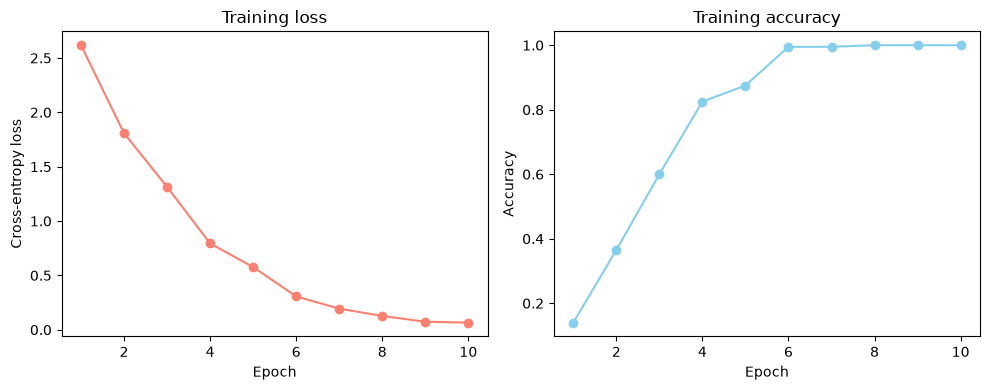

In [21]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(train_loss_history) + 1)

ax_loss.plot(epochs, train_loss_history, color=static_cmap[0], marker="o")
ax_loss.set_title("Training loss")
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Cross-entropy loss")

ax_acc.plot(epochs, train_acc_history, color=static_cmap[1], marker="o")
ax_acc.set_title("Training accuracy")
ax_acc.set_xlabel("Epoch")
ax_acc.set_ylabel("Accuracy")

plt.tight_layout()
plt.show()

### Model Testing and Evaluation

In [22]:
# Set up of multiclass metrics
acc = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
precision = torchmetrics.Precision(task="multiclass", num_classes=10, average="macro").to(device)
recall = torchmetrics.Recall(task="multiclass", num_classes=10, average="macro").to(device)

# Iterate over the dataset batches
model.eval()
with torch.no_grad():
   for images, labels in dataloader_test:
       images, labels = images.to(device), labels.to(device)
       # Get predicted probabilities for test data batch
       outputs = model(images)
       _, preds = torch.max(outputs, 1)
       acc.update(preds, labels)
       precision.update(preds, labels)
       recall.update(preds, labels)

#Compute total test metrics
print(f"Test accuracy: {acc.compute():.4f}")
print(f"Test precision (macro): {precision.compute():.4f}")
print(f"Test recall (macro): {recall.compute():.4f}")

Test accuracy: 0.7800
Test precision (macro): 0.8548
Test recall (macro): 0.7800


#### Classification Matrix and Prediction Probability Distribution

Listen to a randomly chosen recording of the test speaker (picked with the fixed seed, so it is the same on every run) before scoring the test set below.

In [23]:
# Running index of the noise previews; each one picks its recording and noise with seed
# gen_seed + noise_index, counting up from 1 at the first noise preview
noise_index = 0

test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
    audio_dataset, testing_speaker, seed=gen_seed + noise_index)
label_var = f"Clear test audio — word: {test_word}"
speakreg.play_audio(test_signal, test_rate, label=label_var)

Clear test audio — word: six



Test Performance:
              precision    recall  f1-score   support

        zero     1.0000    0.6000    0.7500         5
         one     1.0000    0.6000    0.7500         5
         two     1.0000    0.8000    0.8889         5
       three     0.6667    0.8000    0.7273         5
        four     1.0000    0.6000    0.7500         5
        five     1.0000    0.6000    0.7500         5
         six     1.0000    1.0000    1.0000         5
       seven     0.5000    1.0000    0.6667         5
       eight     0.7143    1.0000    0.8333         5
        nine     0.6667    0.8000    0.7273         5

    accuracy                         0.7800        50
   macro avg     0.8548    0.7800    0.7843        50
weighted avg     0.8548    0.7800    0.7843        50



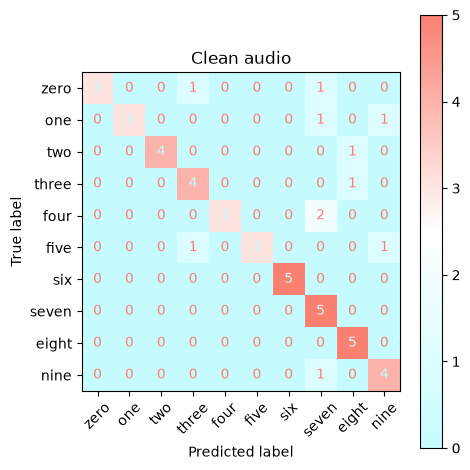

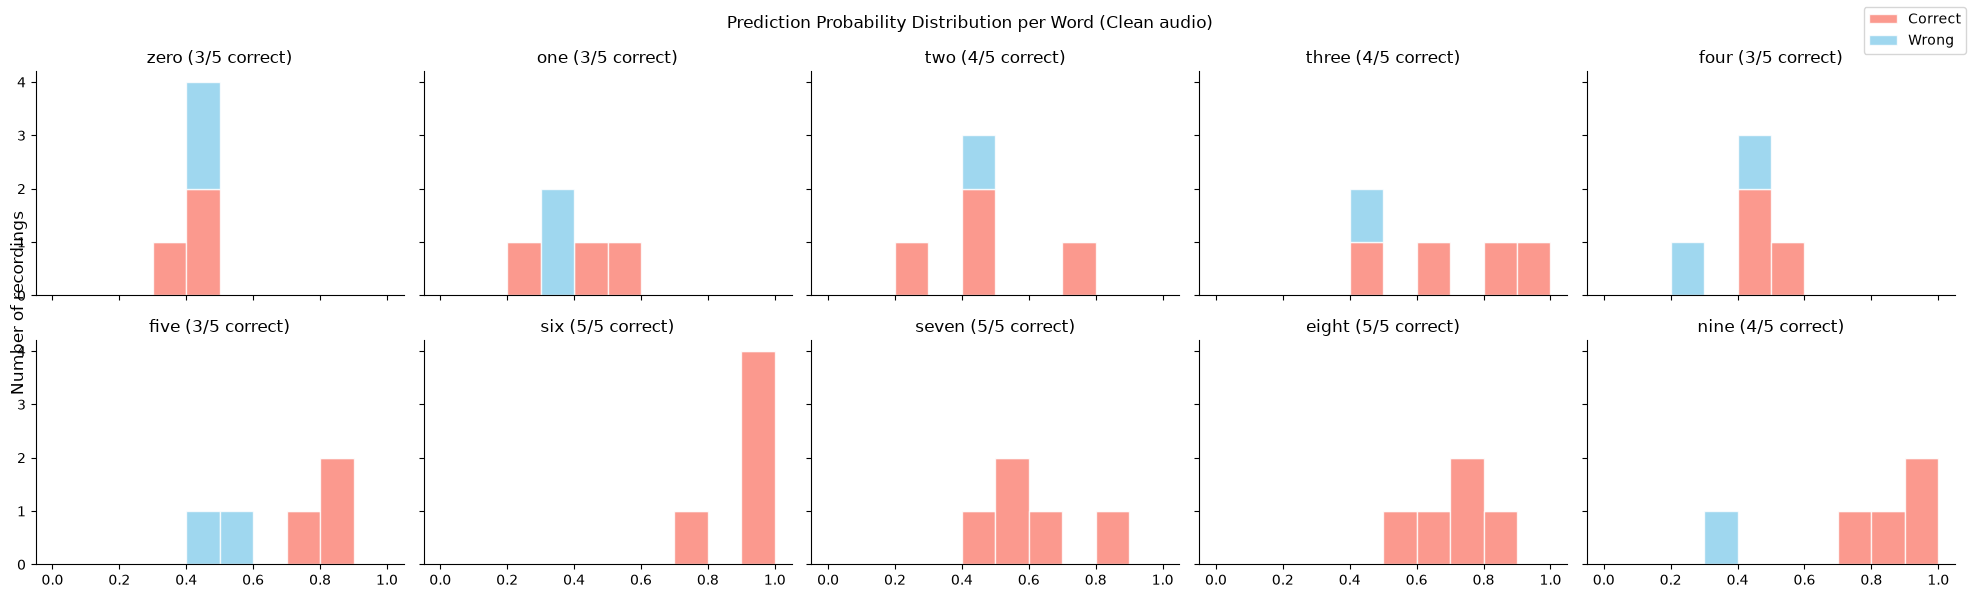

In [24]:
test_results = speakreg.model_output(model, dataloader_test, numbers, static_cmap, cmap, device,
                                     "Clean audio")

# Collect every evaluation for the comparison in section 7
model_results = {"Clean speech": test_results}

## 5. Model testing - Constant Noise Applied

The model trained on clear speech is also evaluated after adding constant background noise on the test speaker's recordings. No addition training data is provided to the model, which is only trained on clear speech.

Two noise types are added:
- **White noise**;
- **Pink noise**.

Noise is added to the raw waveforms at a fixed signal-to-noise ratio (SNR). Features are then recomputed and standardised with the training-set statistics, so the model sees the same preprocessing as for clear speech.

Below the results of each noise type, the randomly chosen test recording named in their titles is compared clean and noisy: first as waveforms, then as the log-mel spectrograms the model actually receives.

### Lesser noise application - 30dB

===== White noise at 30 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.5000    0.6000    0.5455         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.3333    0.4000    0.3636         5
        four     1.0000    0.2000    0.3333         5
        five     0.2500    0.6000    0.3529         5
         six     0.2941    1.0000    0.4545         5
       seven     1.0000    0.4000    0.5714         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.6667    0.8000    0.7273         5

    accuracy                         0.4000        50
   macro avg     0.4044    0.4000    0.3349        50
weighted avg     0.4044    0.4000    0.3349        50



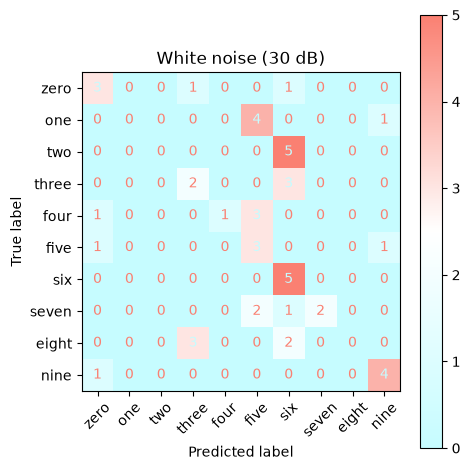

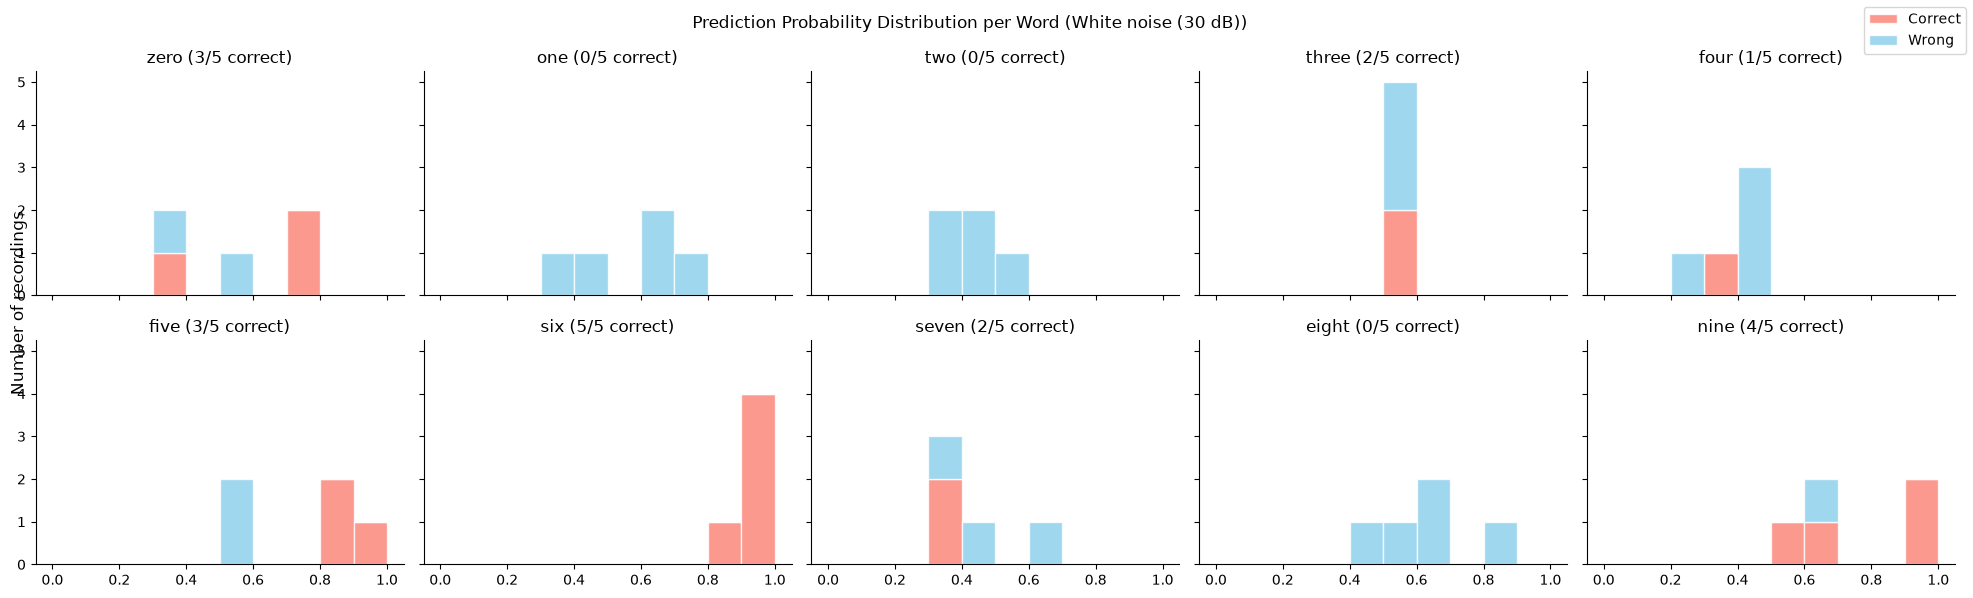

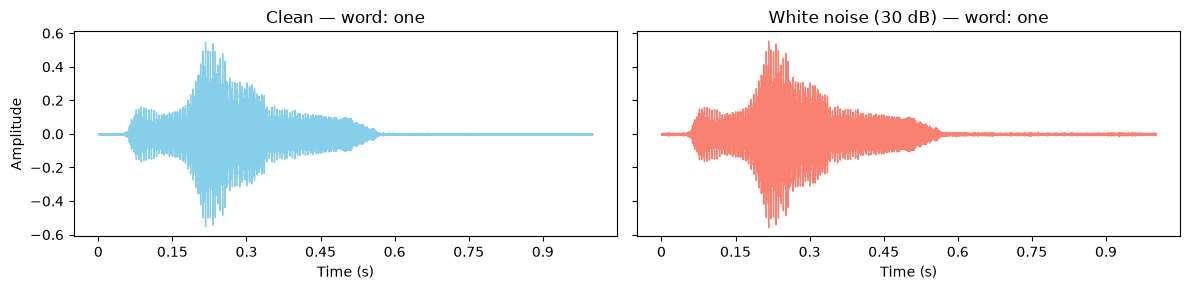

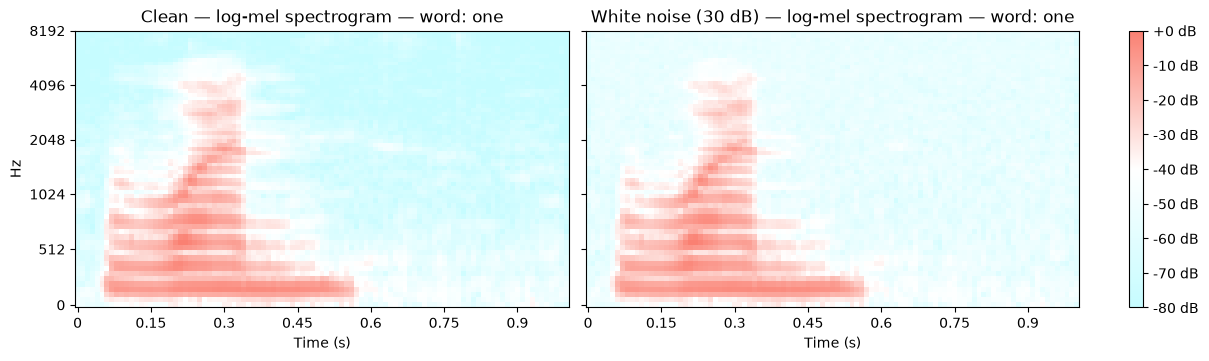

===== Pink noise at 30 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.6250    1.0000    0.7692         5
         one     0.0000    0.0000    0.0000         5
         two     1.0000    0.6000    0.7500         5
       three     0.5714    0.8000    0.6667         5
        four     0.7500    0.6000    0.6667         5
        five     0.3333    0.6000    0.4286         5
         six     0.6250    1.0000    0.7692         5
       seven     1.0000    0.6000    0.7500         5
       eight     1.0000    0.2000    0.3333         5
        nine     0.5714    0.8000    0.6667         5

    accuracy                         0.6200        50
   macro avg     0.6476    0.6200    0.5800        50
weighted avg     0.6476    0.6200    0.5800        50



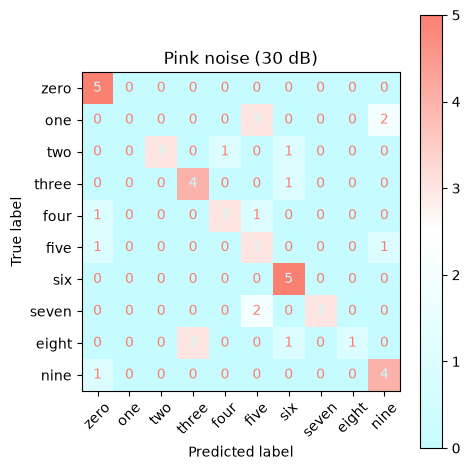

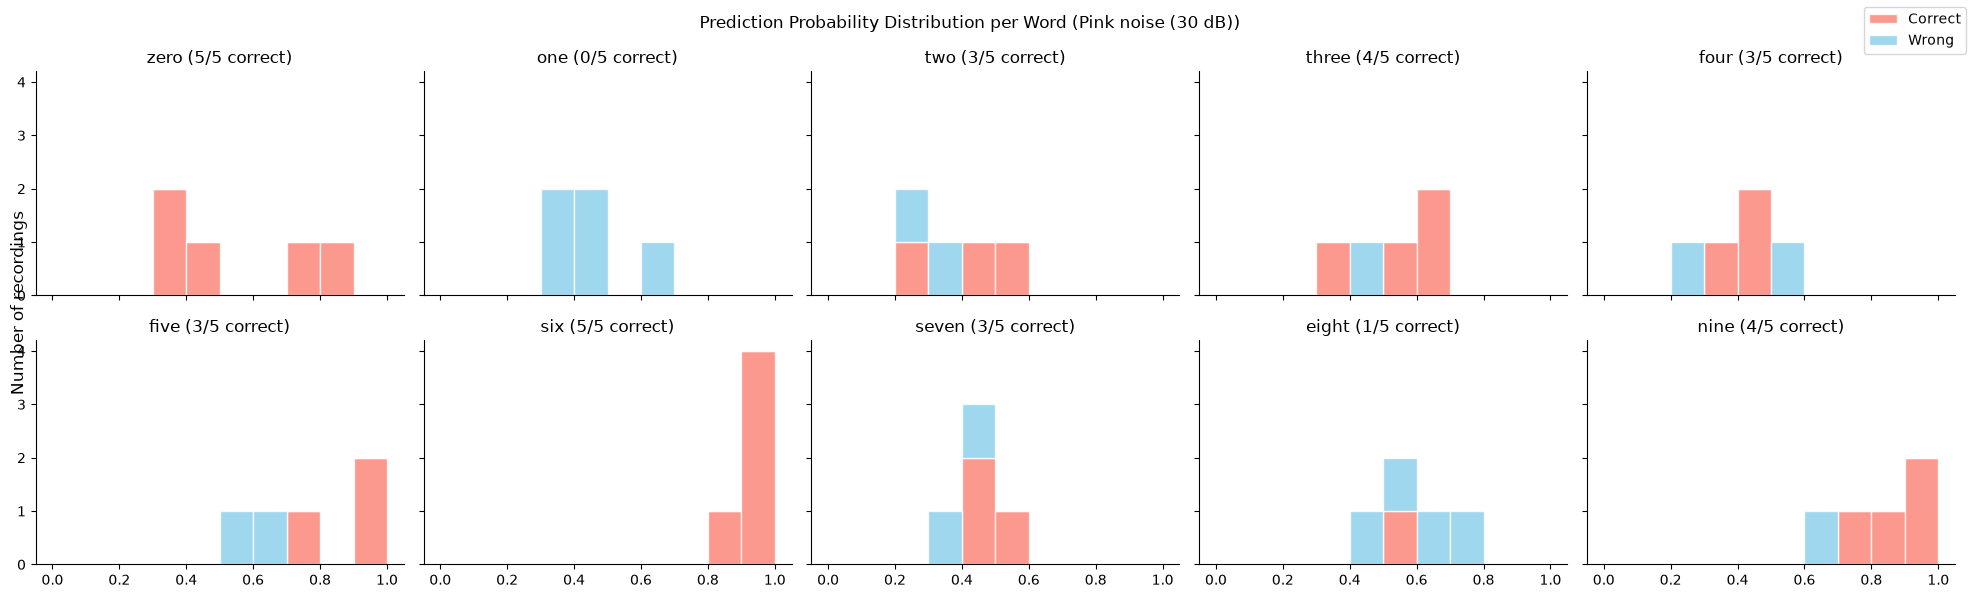

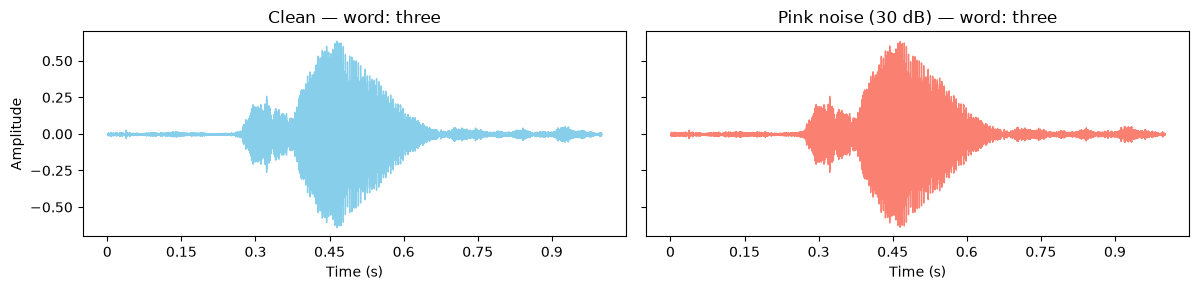

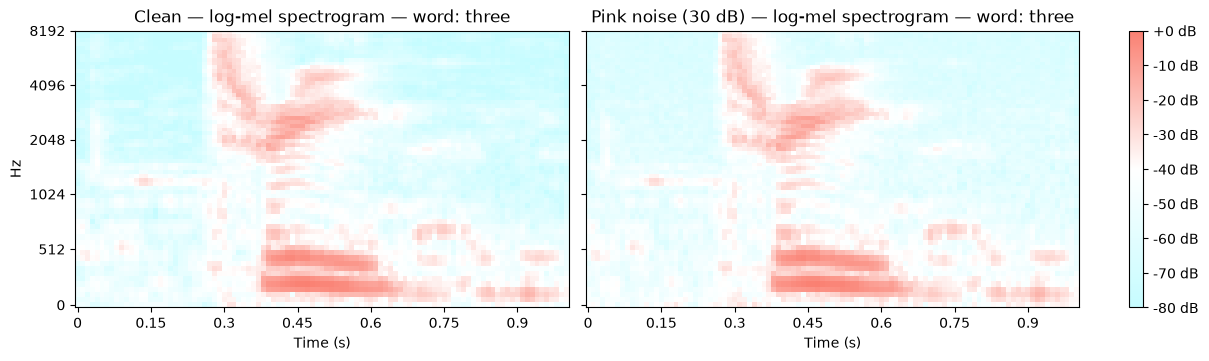

In [25]:
snr_db = 30  # signal-to-noise ratio in decibels; lower means louder noise

noise_loaders = {
    kind: speakreg.noisy_test_loader(audio_dataset, features, numbers, testing_speaker,
                                     kind=kind, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)
    for kind in ("white", "pink")
}

for kind, loader in noise_loaders.items():
    noise_index += 1
    test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
        audio_dataset, testing_speaker, seed=gen_seed + noise_index)
    condition = f"{kind.capitalize()} noise ({snr_db} dB)"

    print(f"===== {kind.capitalize()} noise at {snr_db} dB SNR =====")
    model_results[condition] = speakreg.model_output(
        model, loader, numbers, static_cmap, cmap, device, condition)
    speakreg.preview_synthetic_noise(test_signal, test_rate, test_word,
                                     kind, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

### Moderate noise application - 20dB

===== White noise at 20 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.2857    0.8000    0.4211         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.4000    0.4000    0.4000         5
        four     0.0000    0.0000    0.0000         5
        five     0.5000    0.8000    0.6154         5
         six     0.2381    1.0000    0.3846         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     1.0000    0.4000    0.5714         5

    accuracy                         0.3400        50
   macro avg     0.2424    0.3400    0.2392        50
weighted avg     0.2424    0.3400    0.2392        50



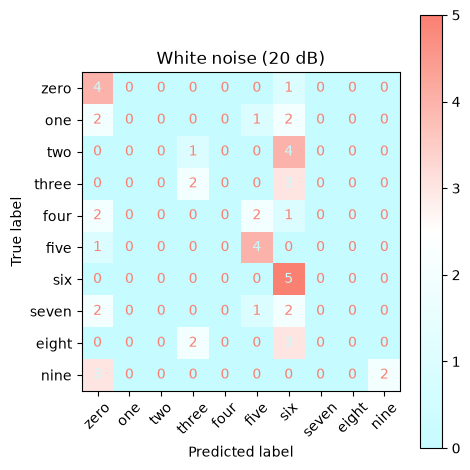

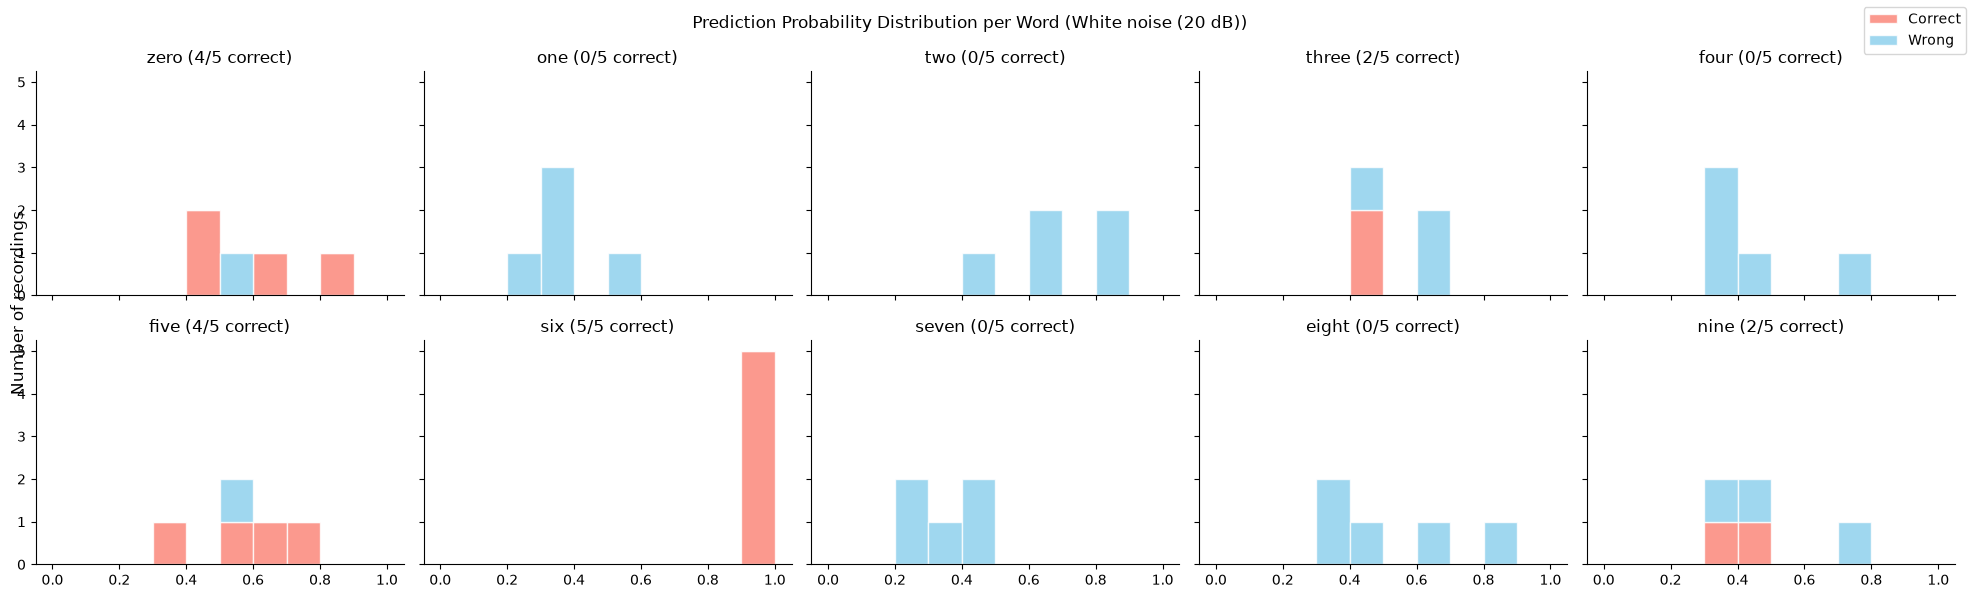

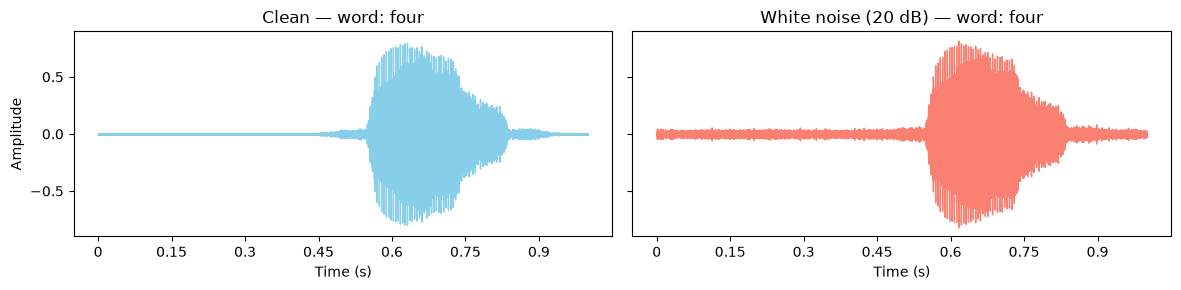

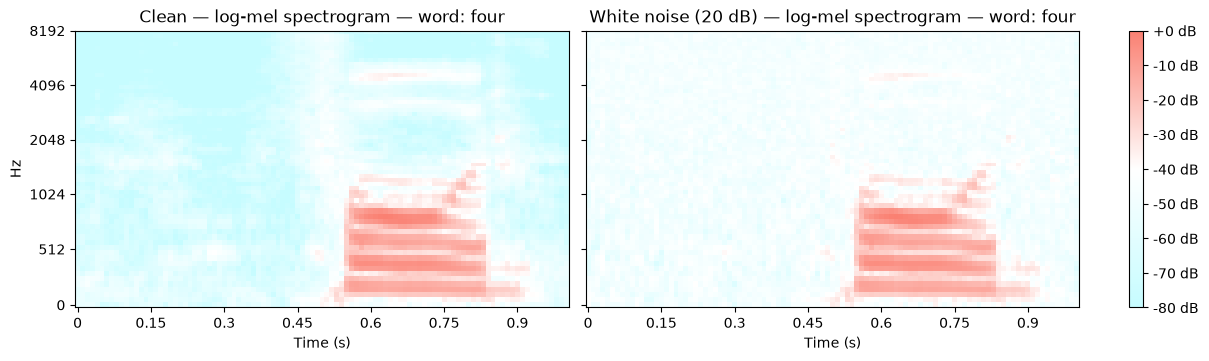

===== Pink noise at 20 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.2778    1.0000    0.4348         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.5000    0.4000    0.4444         5
        four     0.0000    0.0000    0.0000         5
        five     0.3750    0.6000    0.4615         5
         six     0.3846    1.0000    0.5556         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.5714    0.8000    0.6667         5

    accuracy                         0.3800        50
   macro avg     0.2109    0.3800    0.2563        50
weighted avg     0.2109    0.3800    0.2563        50



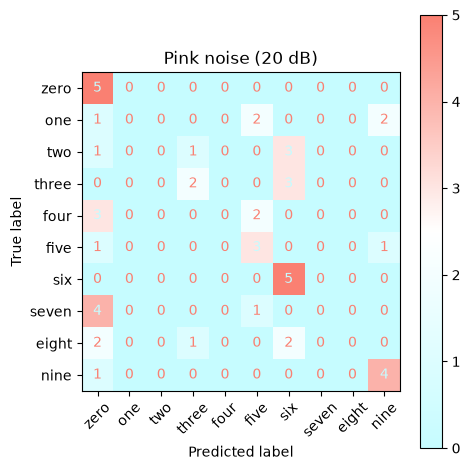

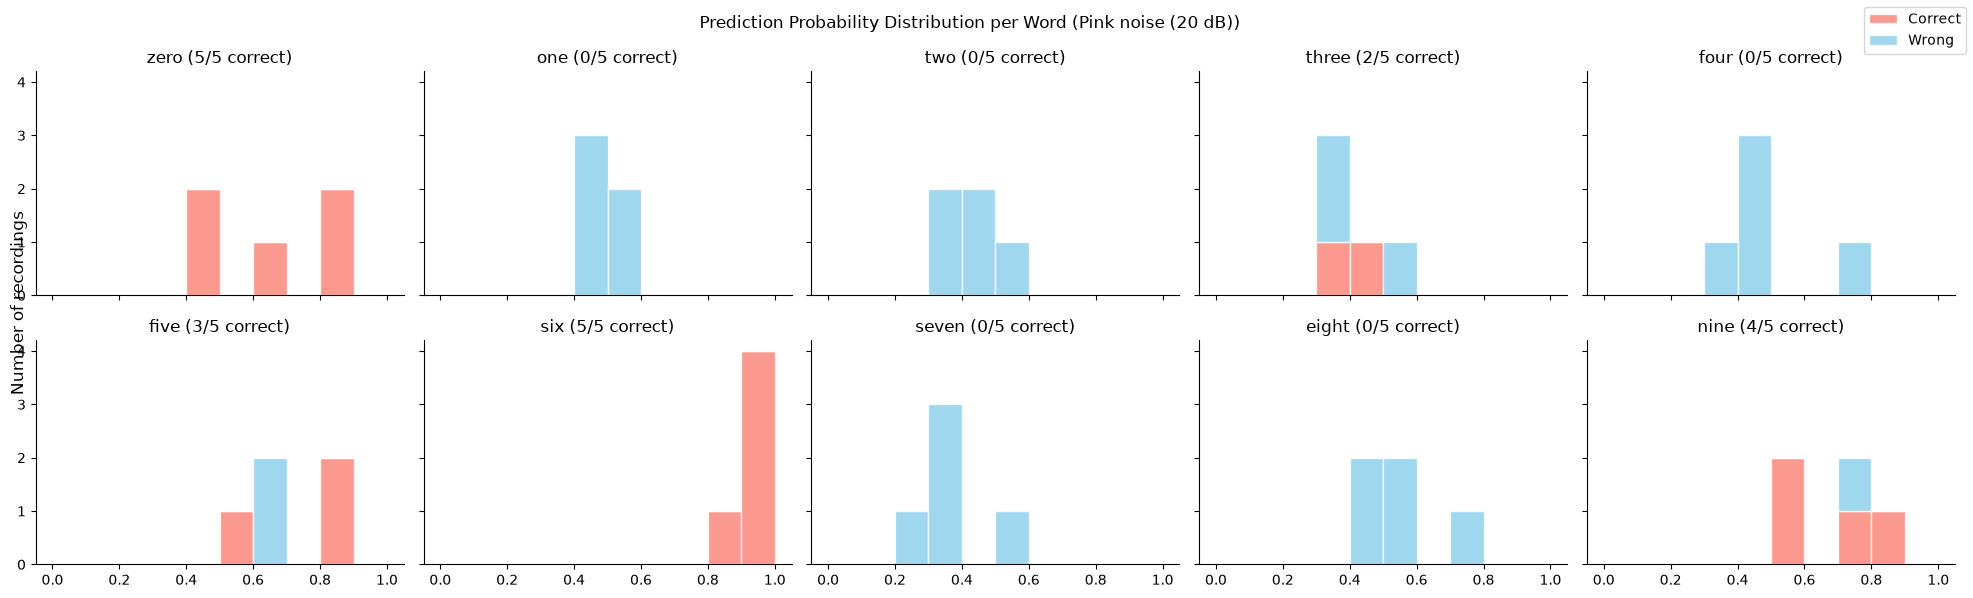

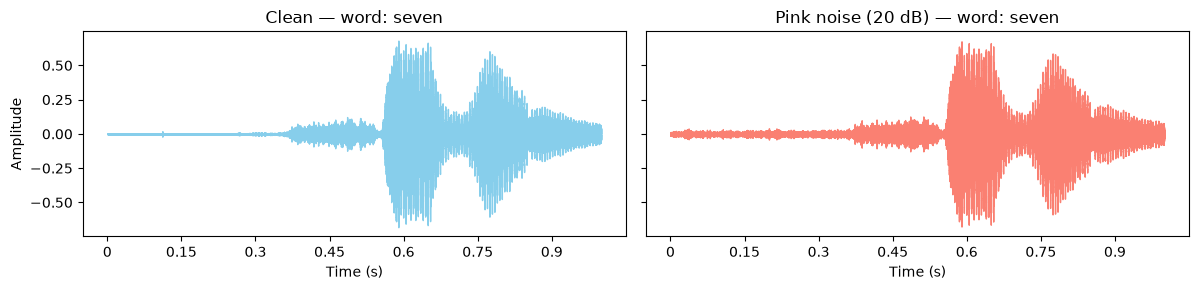

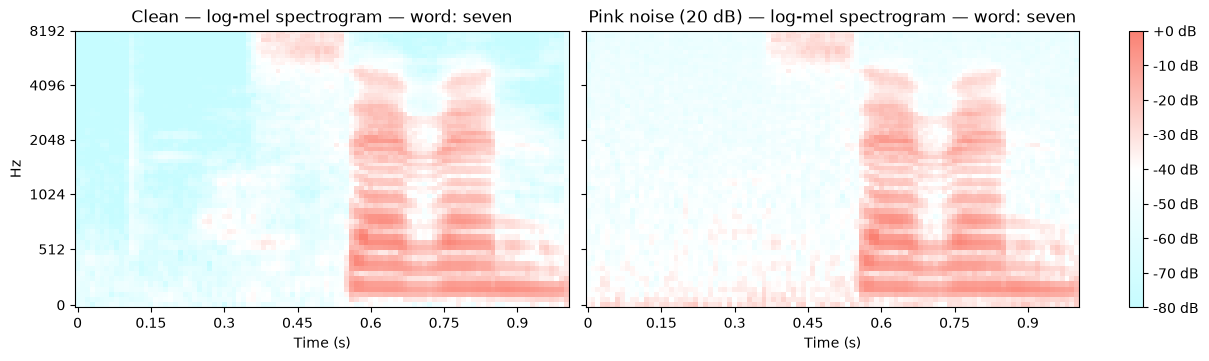

In [26]:
snr_db = 20  # signal-to-noise ratio in decibels; lower means louder noise

noise_loaders = {
    kind: speakreg.noisy_test_loader(audio_dataset, features, numbers, testing_speaker,
                                     kind=kind, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)
    for kind in ("white", "pink")
}

for kind, loader in noise_loaders.items():
    noise_index += 1
    test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
        audio_dataset, testing_speaker, seed=gen_seed + noise_index)
    condition = f"{kind.capitalize()} noise ({snr_db} dB)"

    print(f"===== {kind.capitalize()} noise at {snr_db} dB SNR =====")
    model_results[condition] = speakreg.model_output(
        model, loader, numbers, static_cmap, cmap, device, condition)
    speakreg.preview_synthetic_noise(test_signal, test_rate, test_word,
                                     kind, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

### Higher noise application - 10dB

===== White noise at 10 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.1136    1.0000    0.2041         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.0000    0.0000    0.0000         5
        four     0.0000    0.0000    0.0000         5
        five     0.0000    0.0000    0.0000         5
         six     0.8333    1.0000    0.9091         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.0000    0.0000    0.0000         5

    accuracy                         0.2000        50
   macro avg     0.0947    0.2000    0.1113        50
weighted avg     0.0947    0.2000    0.1113        50



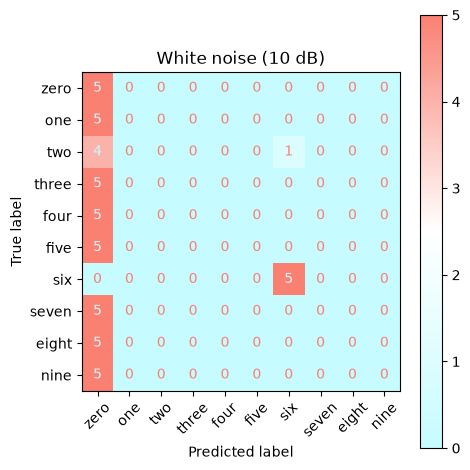

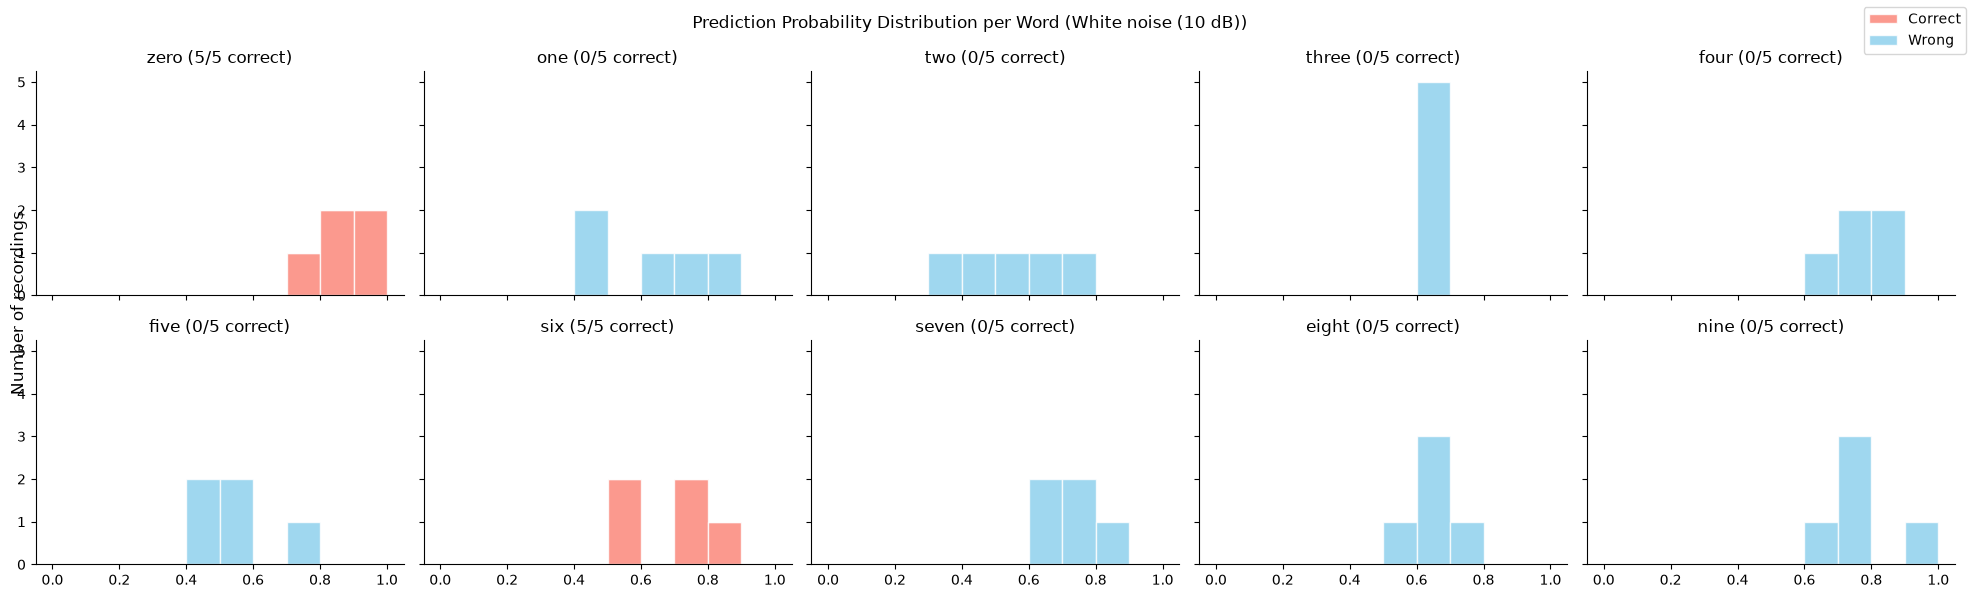

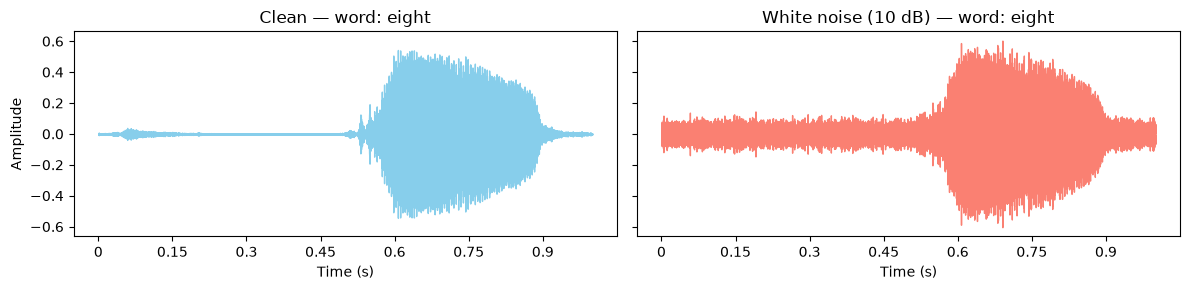

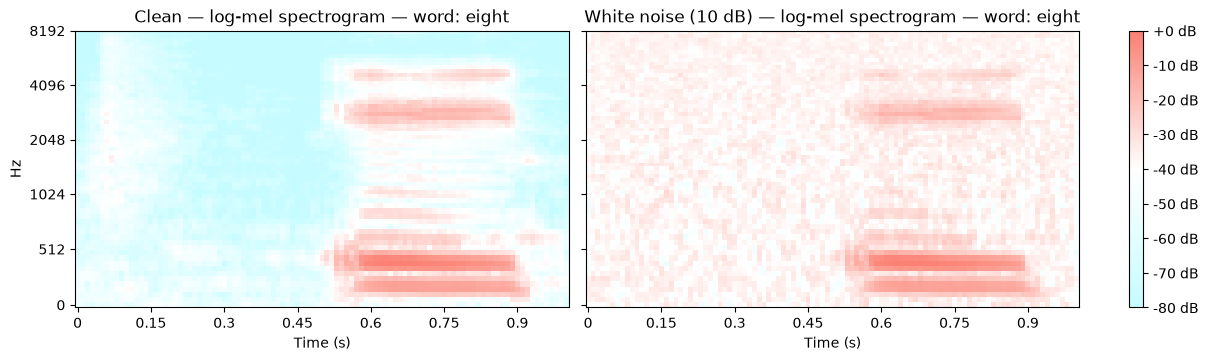

===== Pink noise at 10 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.1136    1.0000    0.2041         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.0000    0.0000    0.0000         5
        four     0.0000    0.0000    0.0000         5
        five     0.0000    0.0000    0.0000         5
         six     1.0000    1.0000    1.0000         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.0000    0.0000    0.0000         5

    accuracy                         0.2000        50
   macro avg     0.1114    0.2000    0.1204        50
weighted avg     0.1114    0.2000    0.1204        50



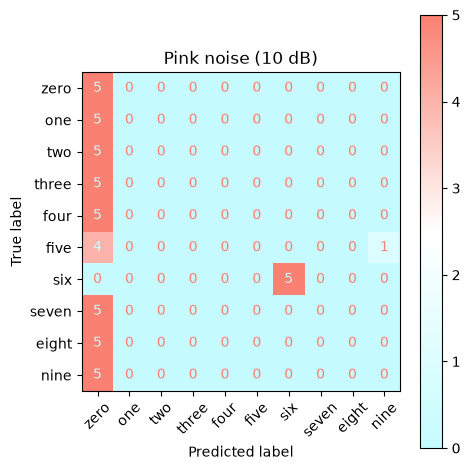

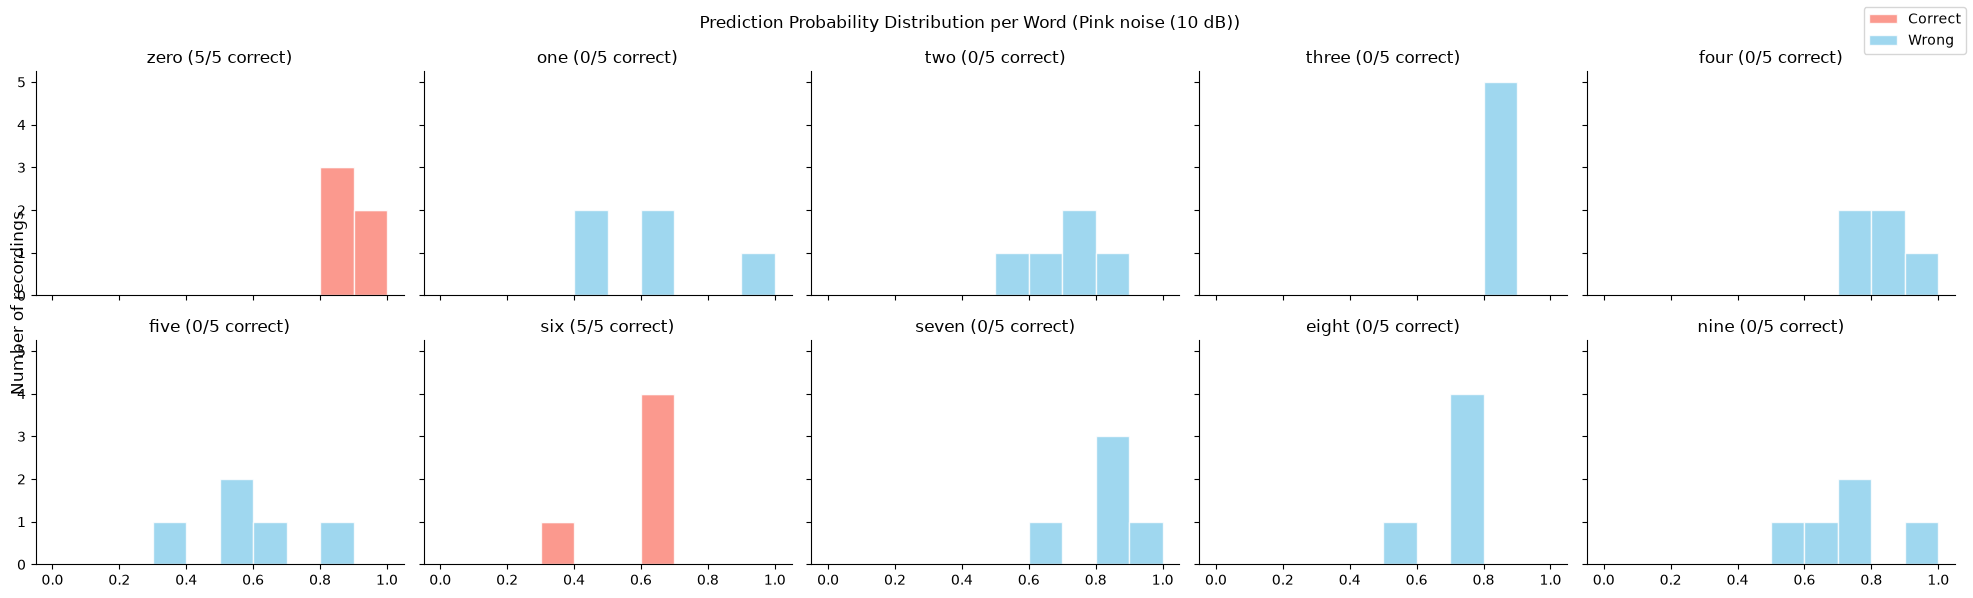

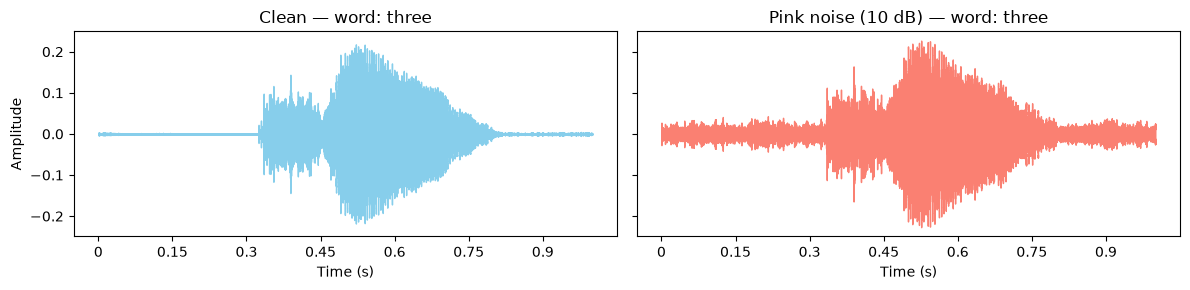

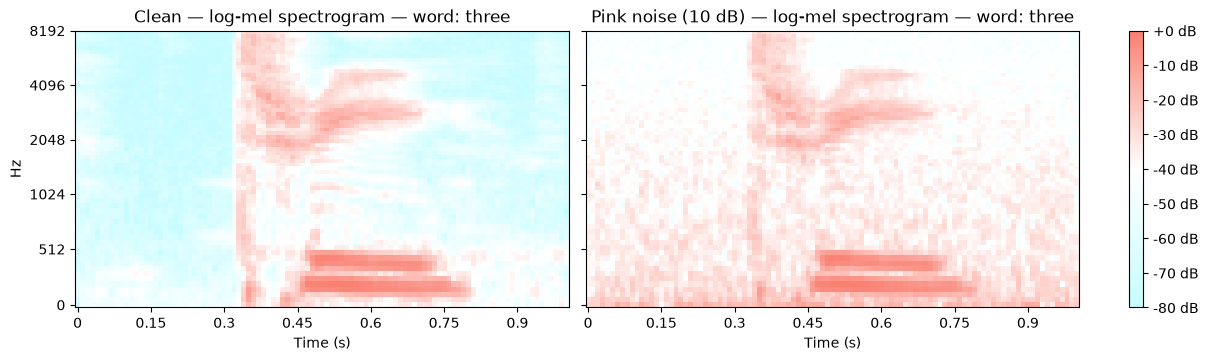

In [27]:
snr_db = 10

noise_loaders = {
    kind: speakreg.noisy_test_loader(audio_dataset, features, numbers, testing_speaker,
                                     kind=kind, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)
    for kind in ("white", "pink")
}

for kind, loader in noise_loaders.items():
    noise_index += 1
    test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
        audio_dataset, testing_speaker, seed=gen_seed + noise_index)
    condition = f"{kind.capitalize()} noise ({snr_db} dB)"

    print(f"===== {kind.capitalize()} noise at {snr_db} dB SNR =====")
    model_results[condition] = speakreg.model_output(
        model, loader, numbers, static_cmap, cmap, device, condition)
    speakreg.preview_synthetic_noise(test_signal, test_rate, test_word,
                                     kind, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

### High noise application - 0dB

===== White noise at 0 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.1000    1.0000    0.1818         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.0000    0.0000    0.0000         5
        four     0.0000    0.0000    0.0000         5
        five     0.0000    0.0000    0.0000         5
         six     0.0000    0.0000    0.0000         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.0000    0.0000    0.0000         5

    accuracy                         0.1000        50
   macro avg     0.0100    0.1000    0.0182        50
weighted avg     0.0100    0.1000    0.0182        50



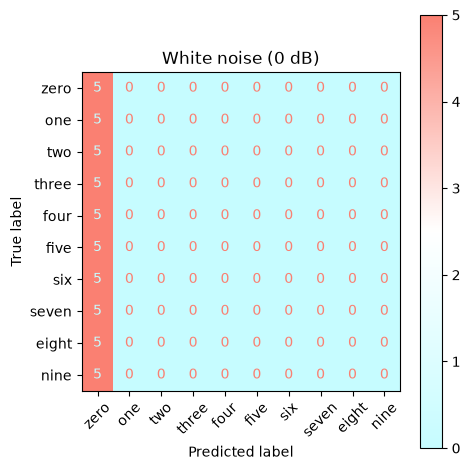

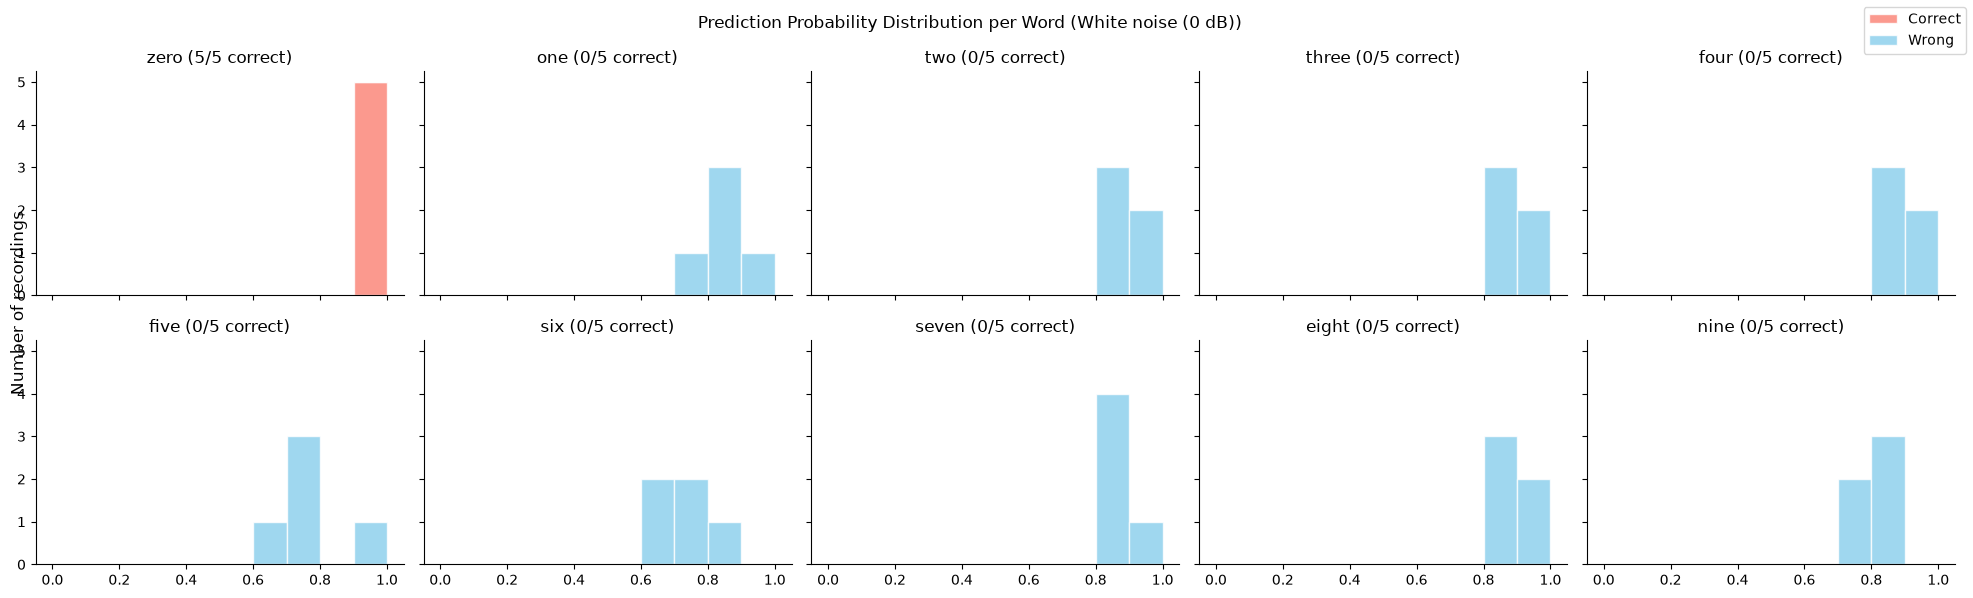

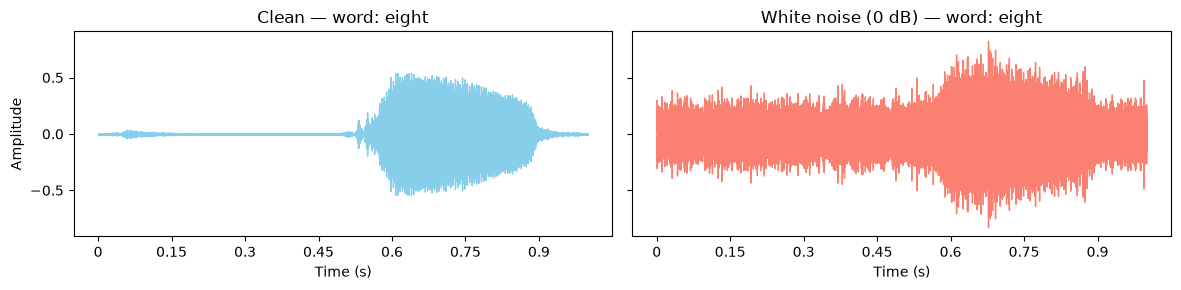

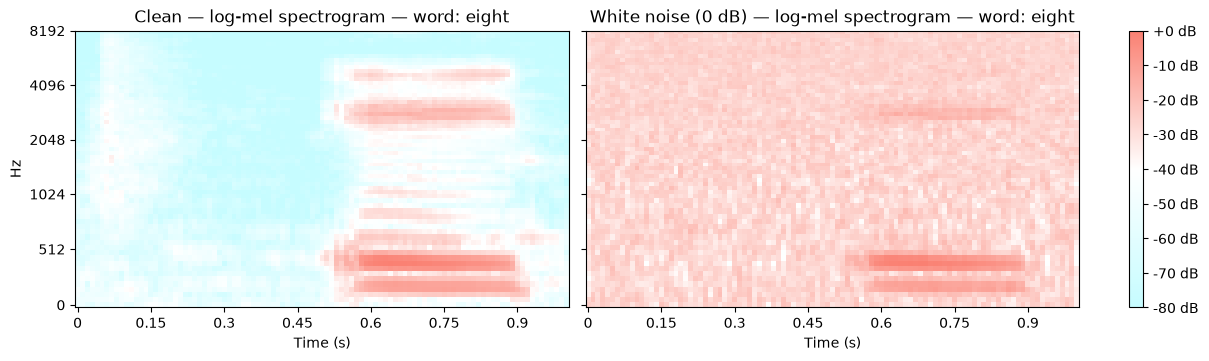

===== Pink noise at 0 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.1000    1.0000    0.1818         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.0000    0.0000    0.0000         5
        four     0.0000    0.0000    0.0000         5
        five     0.0000    0.0000    0.0000         5
         six     0.0000    0.0000    0.0000         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.0000    0.0000    0.0000         5

    accuracy                         0.1000        50
   macro avg     0.0100    0.1000    0.0182        50
weighted avg     0.0100    0.1000    0.0182        50



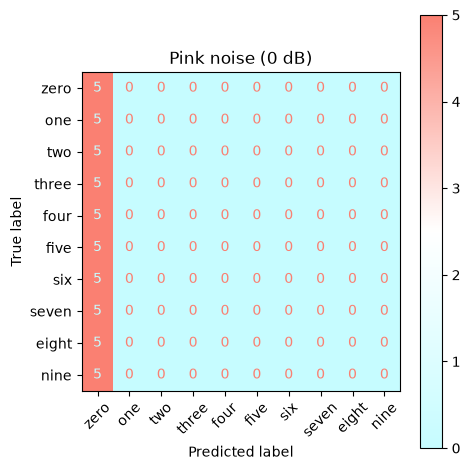

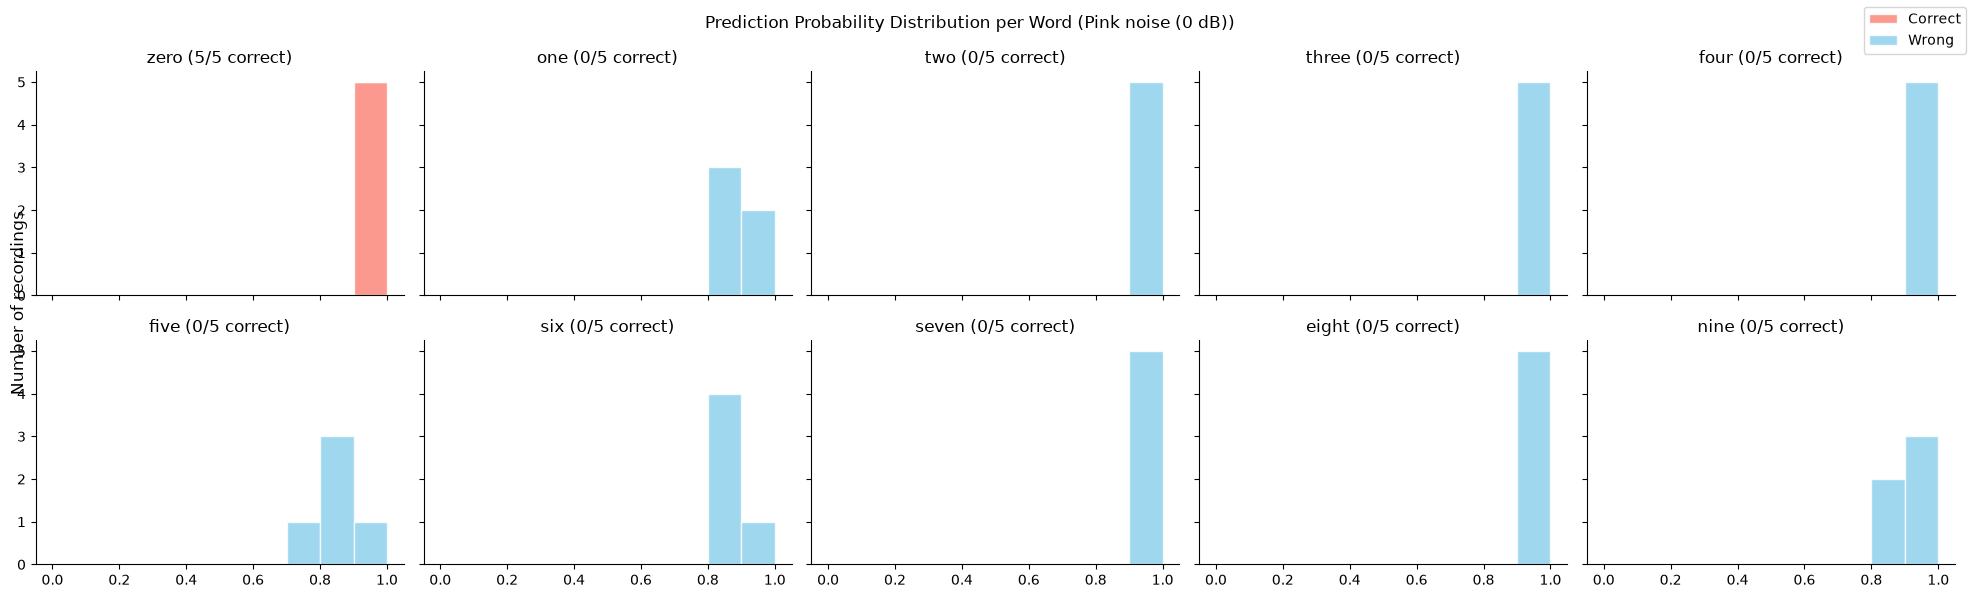

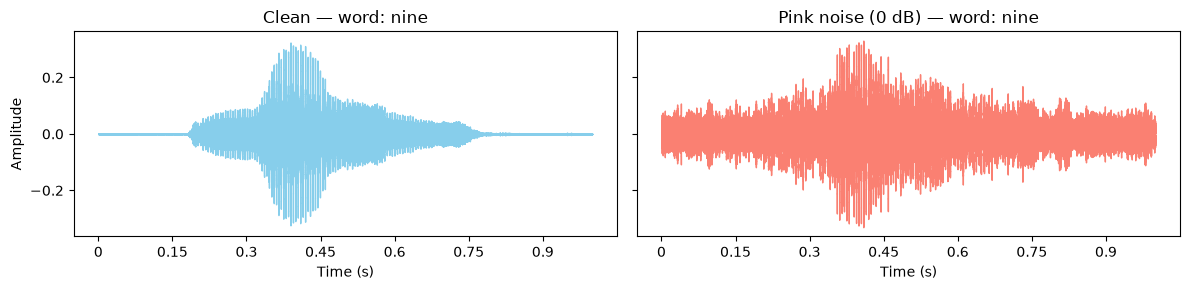

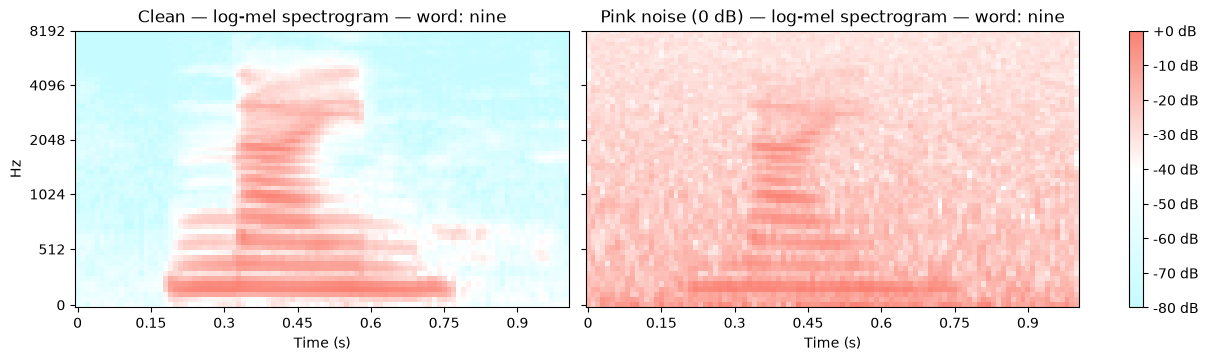

In [28]:
snr_db = 0

noise_loaders = {
    kind: speakreg.noisy_test_loader(audio_dataset, features, numbers, testing_speaker,
                                     kind=kind, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)
    for kind in ("white", "pink")
}

for kind, loader in noise_loaders.items():
    noise_index += 1
    test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
        audio_dataset, testing_speaker, seed=gen_seed + noise_index)
    condition = f"{kind.capitalize()} noise ({snr_db} dB)"

    print(f"===== {kind.capitalize()} noise at {snr_db} dB SNR =====")
    model_results[condition] = speakreg.model_output(
        model, loader, numbers, static_cmap, cmap, device, condition)
    speakreg.preview_synthetic_noise(test_signal, test_rate, test_word,
                                     kind, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

## 6. Model testing - Random (Real World) Noise Applied

The model trained on clear speech is evaluated again on the test speaker's recordings after mixing in a real-world noise recording (rain), instead of the synthetically generated white/pink noise used in section 5.

The rain recording is resampled to the dataset's 16 kHz when loaded and, being five times the length of a single digit recording, is then segmented into non-overlapping clips matching the digit recordings' length. Each test recording is then paired with a randomly chosen segment and mixed at a target SNR.

In [29]:
real_noise_path = master_folder_path / "real_world_sound" / "rain_sound.wav"

rain_signal, rain_sr = librosa.load(real_noise_path, sr=sr_benchmark)
if rain_sr != sr_benchmark:
    raise ValueError(f"rain recording sample rate ({rain_sr}) does not match the dataset's ({sr_benchmark}).")

segment_length = int(round(sr_benchmark * max_duration))
rain_segments = speakreg.segment_noise(rain_signal, segment_length, rng=np.random.default_rng(gen_seed))

print(f"rain recording: {len(rain_signal) / rain_sr:.2f}s at {rain_sr}Hz, segmented into "
      f"{len(rain_segments)} clip(s) of {segment_length / rain_sr:.2f}s each, matching the digit recordings.")

rain recording: 5.00s at 16000Hz, segmented into 5 clip(s) of 1.00s each, matching the digit recordings.


### Lesser real-world noise application - 30dB

===== Rain noise at 30 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.5000    0.8000    0.6154         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.3750    0.6000    0.4615         5
        four     1.0000    0.2000    0.3333         5
        five     0.3333    0.6000    0.4286         5
         six     0.3846    1.0000    0.5556         5
       seven     1.0000    0.4000    0.5714         5
       eight     1.0000    0.2000    0.3333         5
        nine     0.5000    0.8000    0.6154         5

    accuracy                         0.4600        50
   macro avg     0.5093    0.4600    0.3915        50
weighted avg     0.5093    0.4600    0.3915        50



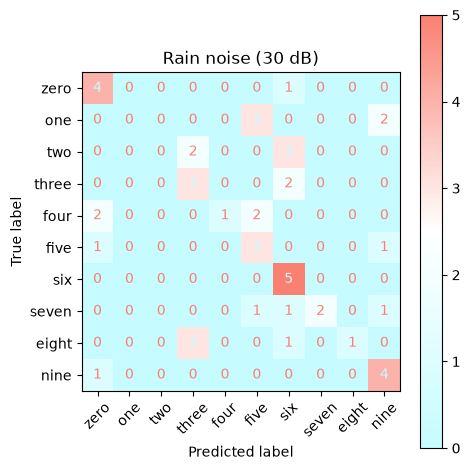

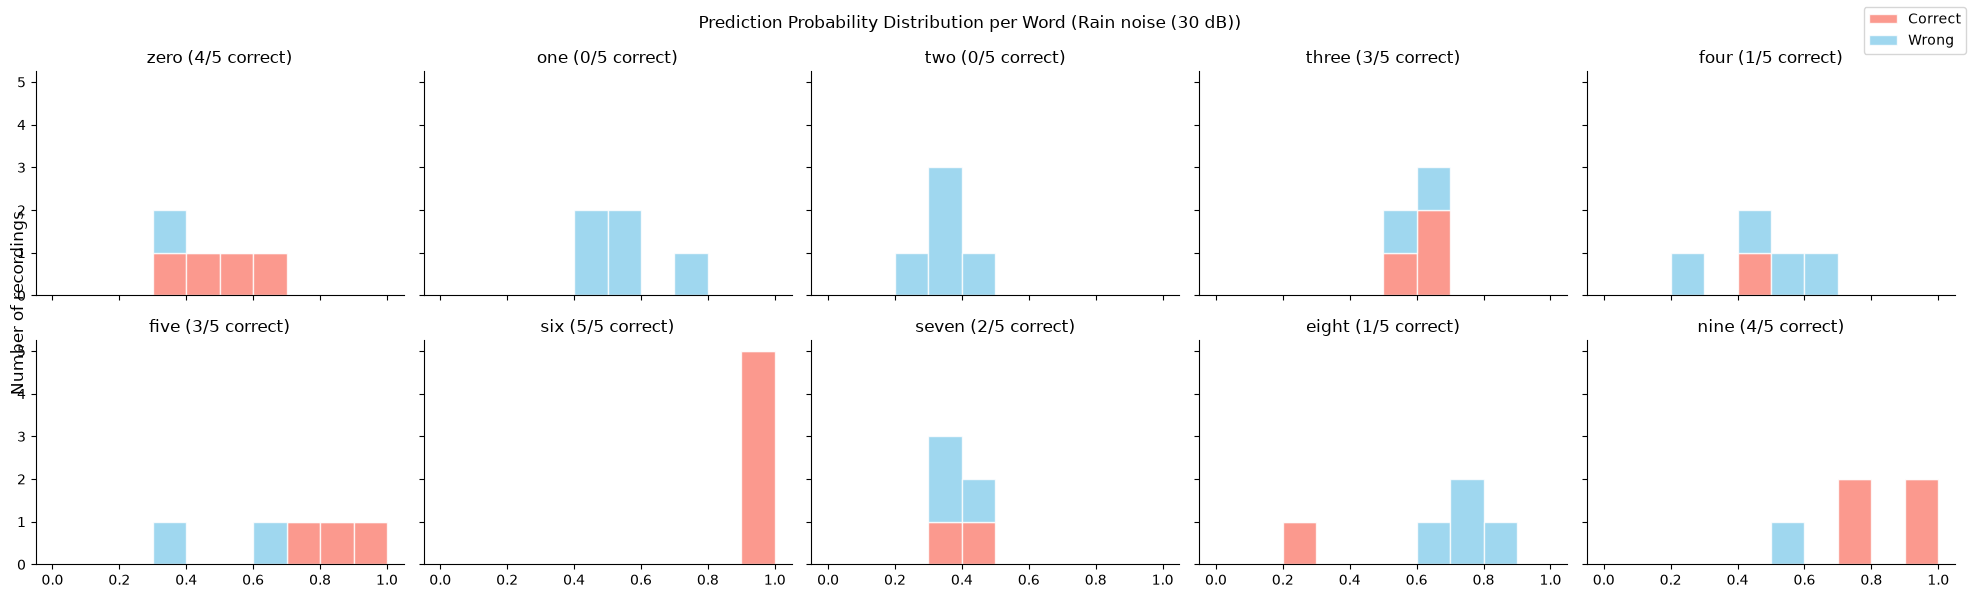

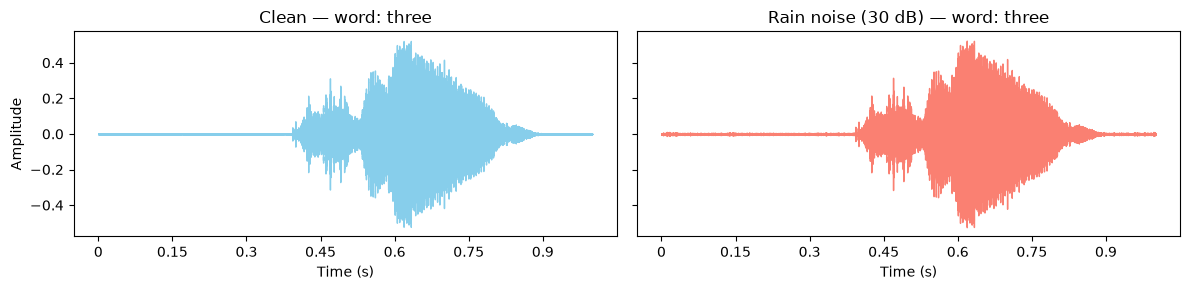

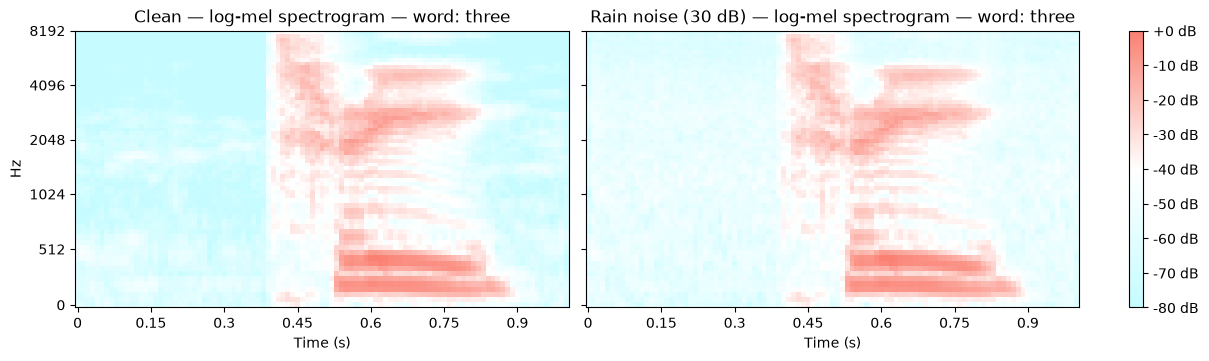

In [30]:
snr_db = 30  # signal-to-noise ratio in decibels; lower means louder noise

rain_loader = speakreg.real_noise_test_loader(audio_dataset, features, numbers, testing_speaker,
                                              rain_segments, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)

noise_index += 1
test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
    audio_dataset, testing_speaker, seed=gen_seed + noise_index)
condition = f"Rain noise ({snr_db} dB)"

print(f"===== Rain noise at {snr_db} dB SNR =====")
model_results[condition] = speakreg.model_output(
    model, rain_loader, numbers, static_cmap, cmap, device, condition)

speakreg.preview_real_noise(test_signal, test_rate, test_word,
                            rain_segments, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

### Moderate real-world noise application - 20dB

===== Rain noise at 20 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.2941    1.0000    0.4545         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.3636    0.8000    0.5000         5
        four     0.0000    0.0000    0.0000         5
        five     0.5000    0.8000    0.6154         5
         six     0.5556    1.0000    0.7143         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.6000    0.6000    0.6000         5

    accuracy                         0.4200        50
   macro avg     0.2313    0.4200    0.2884        50
weighted avg     0.2313    0.4200    0.2884        50



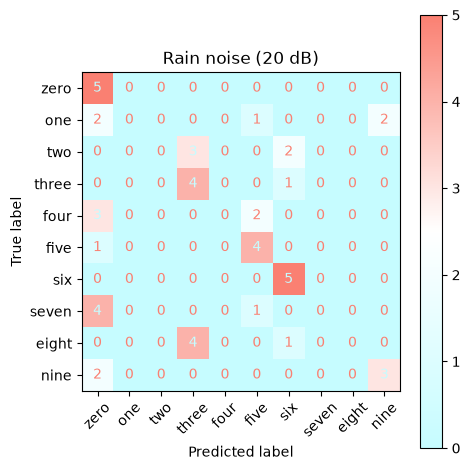

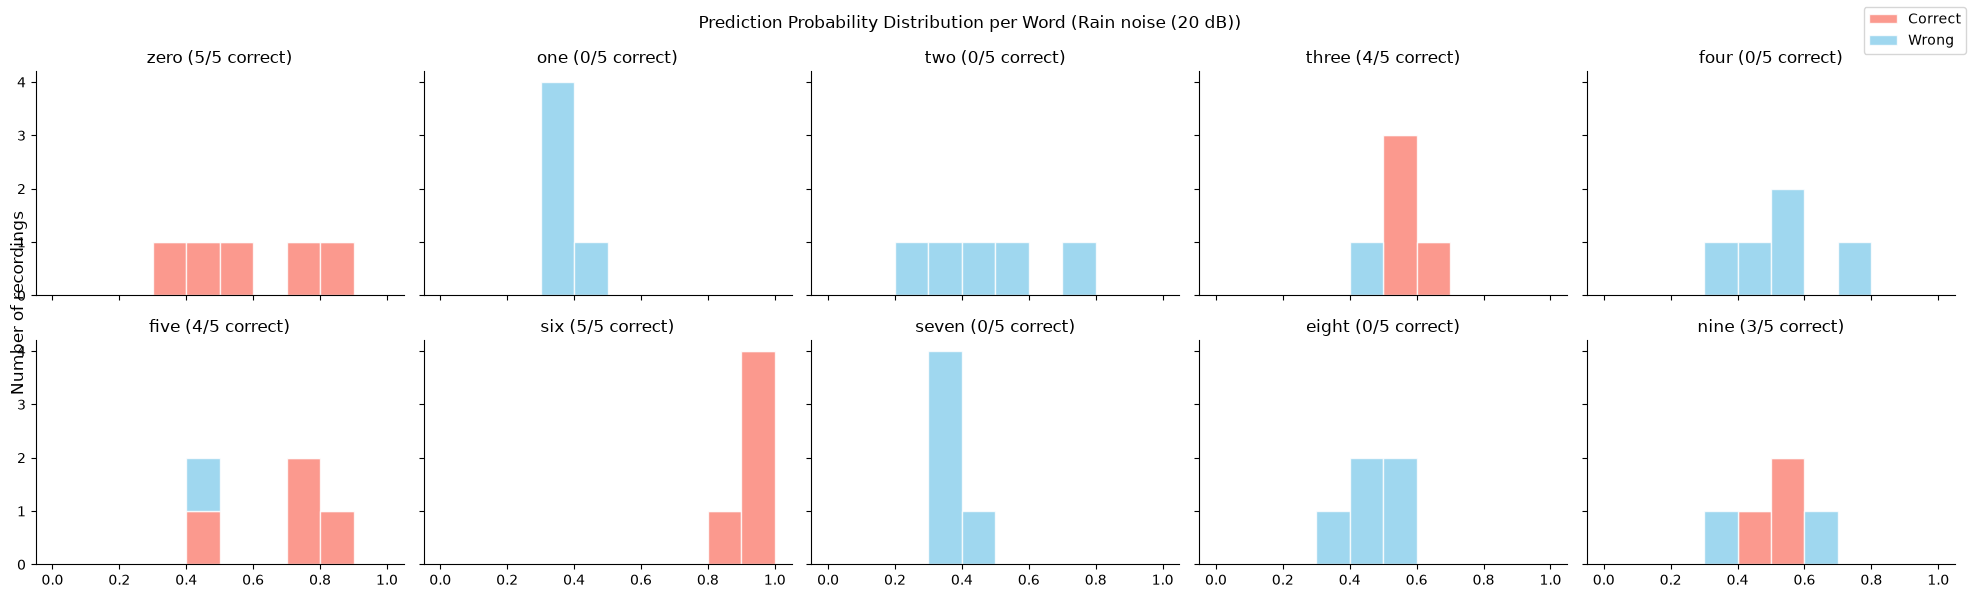

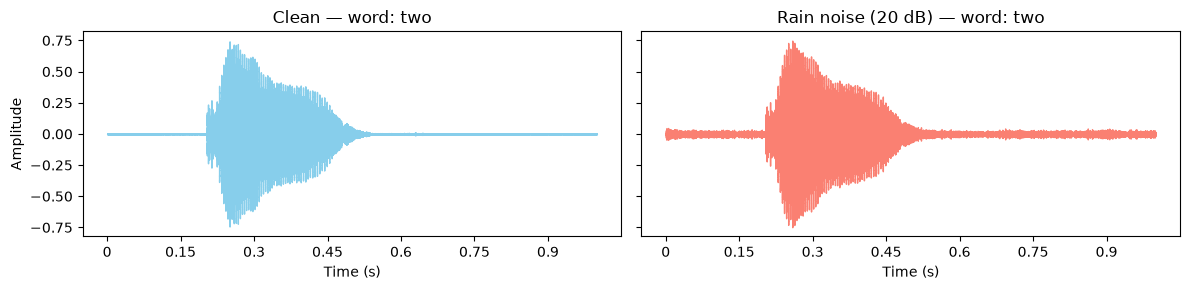

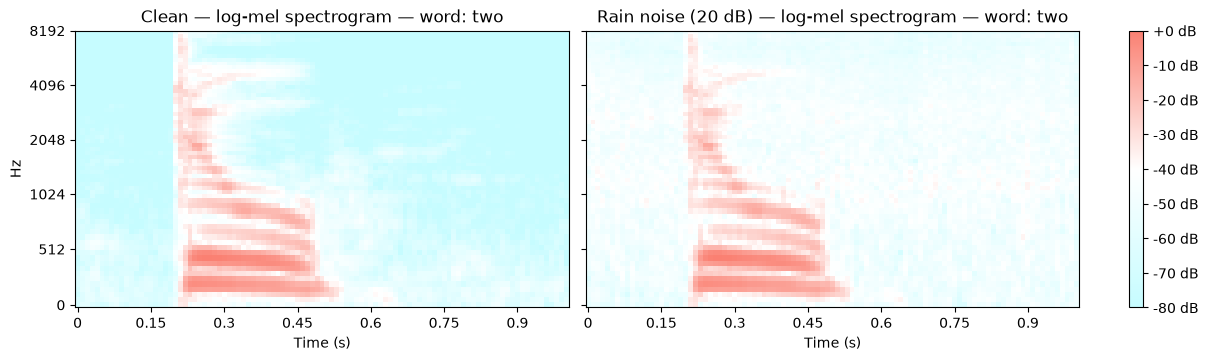

In [31]:
snr_db = 20  # signal-to-noise ratio in decibels; lower means louder noise

rain_loader = speakreg.real_noise_test_loader(audio_dataset, features, numbers, testing_speaker,
                                              rain_segments, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)

noise_index += 1
test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
    audio_dataset, testing_speaker, seed=gen_seed + noise_index)
condition = f"Rain noise ({snr_db} dB)"

print(f"===== Rain noise at {snr_db} dB SNR =====")
model_results[condition] = speakreg.model_output(
    model, rain_loader, numbers, static_cmap, cmap, device, condition)

speakreg.preview_real_noise(test_signal, test_rate, test_word,
                            rain_segments, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

### Higher real-world noise application - 10dB

===== Rain noise at 10 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.1190    1.0000    0.2128         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.0000    0.0000    0.0000         5
        four     0.0000    0.0000    0.0000         5
        five     1.0000    0.6000    0.7500         5
         six     1.0000    0.6000    0.7500         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.0000    0.0000    0.0000         5

    accuracy                         0.2200        50
   macro avg     0.2119    0.2200    0.1713        50
weighted avg     0.2119    0.2200    0.1713        50



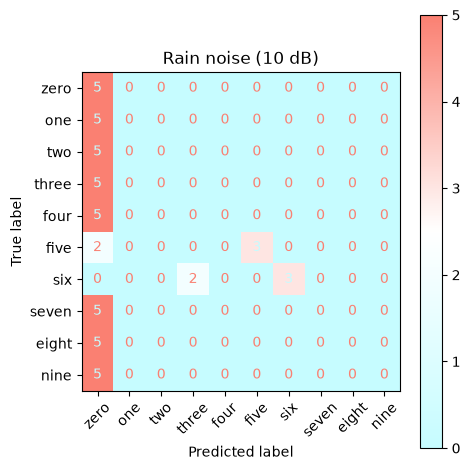

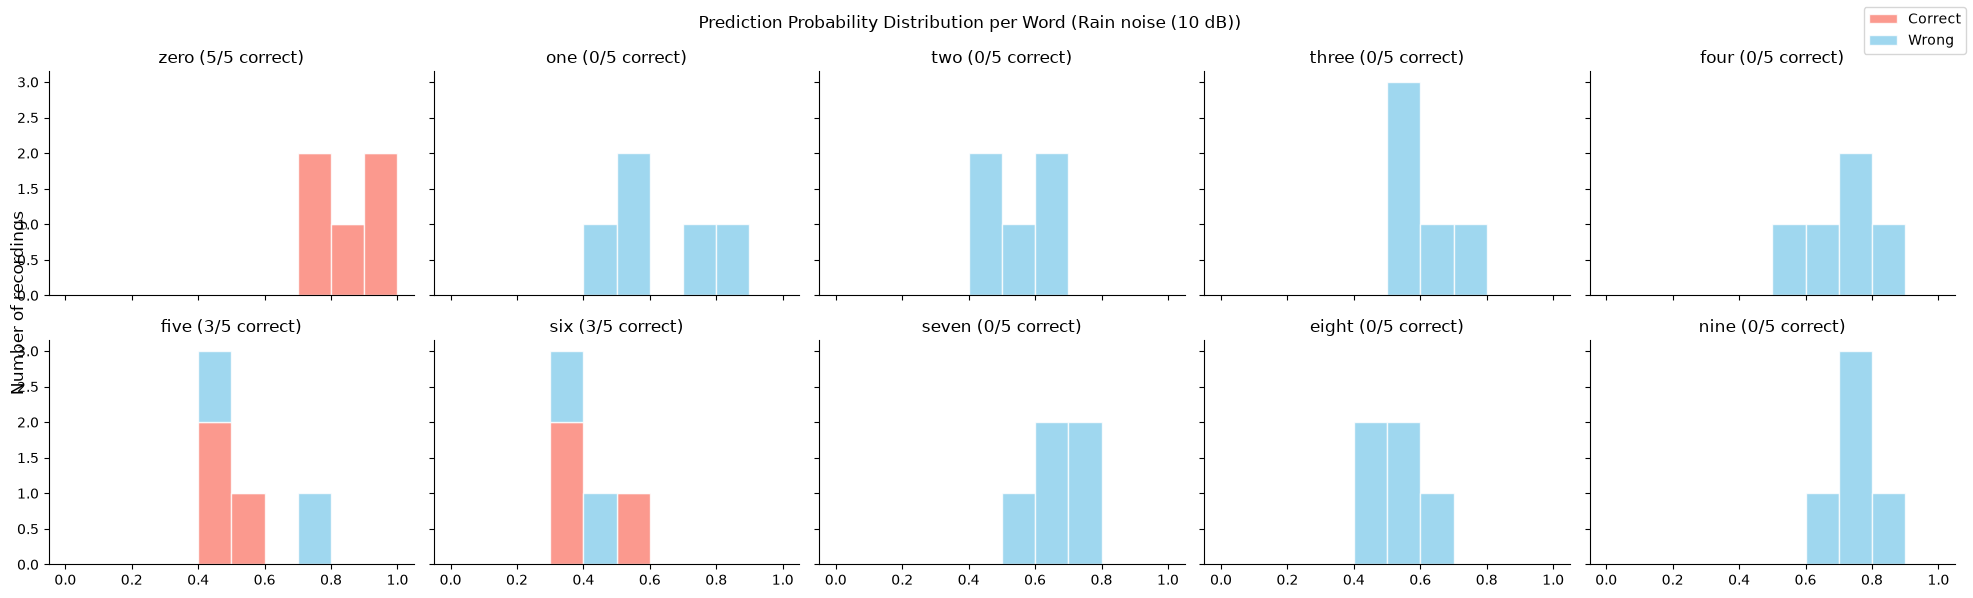

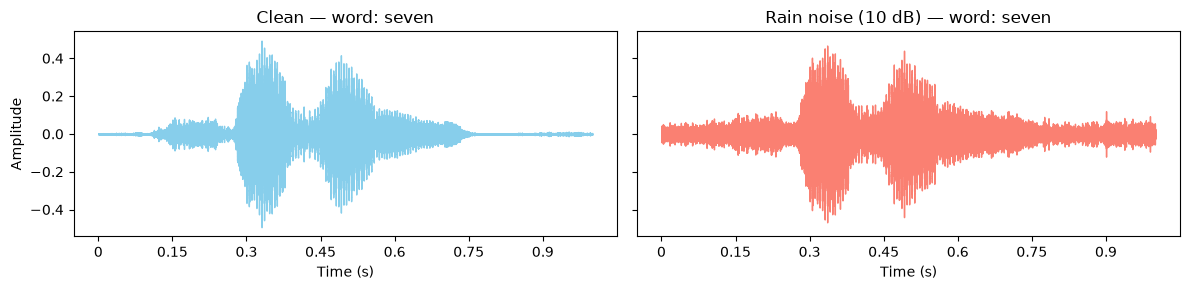

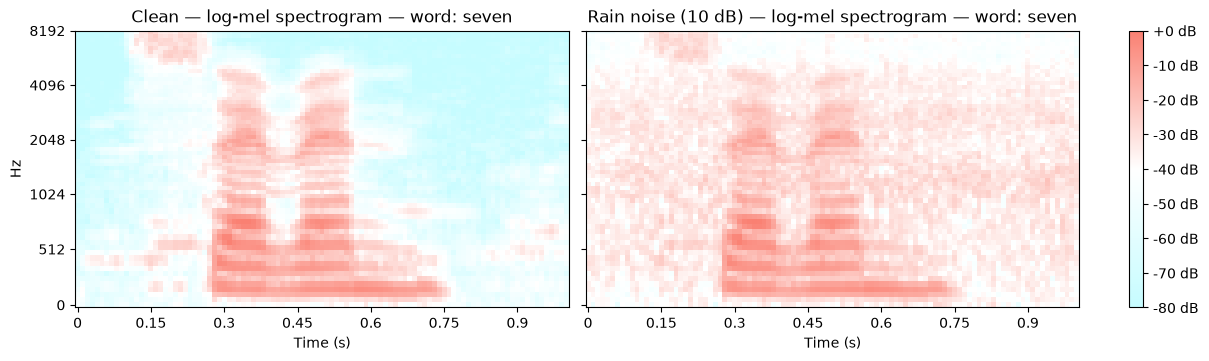

In [32]:
snr_db = 10  # signal-to-noise ratio in decibels; lower means louder noise

rain_loader = speakreg.real_noise_test_loader(audio_dataset, features, numbers, testing_speaker,
                                              rain_segments, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)

noise_index += 1
test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
    audio_dataset, testing_speaker, seed=gen_seed + noise_index)
condition = f"Rain noise ({snr_db} dB)"

print(f"===== Rain noise at {snr_db} dB SNR =====")
model_results[condition] = speakreg.model_output(
    model, rain_loader, numbers, static_cmap, cmap, device, condition)

speakreg.preview_real_noise(test_signal, test_rate, test_word,
                            rain_segments, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

### High real-world noise application - 0dB

===== Rain noise at 0 dB SNR =====

Test Performance:
              precision    recall  f1-score   support

        zero     0.1000    1.0000    0.1818         5
         one     0.0000    0.0000    0.0000         5
         two     0.0000    0.0000    0.0000         5
       three     0.0000    0.0000    0.0000         5
        four     0.0000    0.0000    0.0000         5
        five     0.0000    0.0000    0.0000         5
         six     0.0000    0.0000    0.0000         5
       seven     0.0000    0.0000    0.0000         5
       eight     0.0000    0.0000    0.0000         5
        nine     0.0000    0.0000    0.0000         5

    accuracy                         0.1000        50
   macro avg     0.0100    0.1000    0.0182        50
weighted avg     0.0100    0.1000    0.0182        50



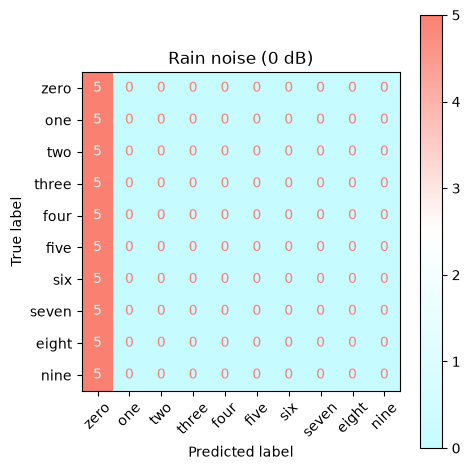

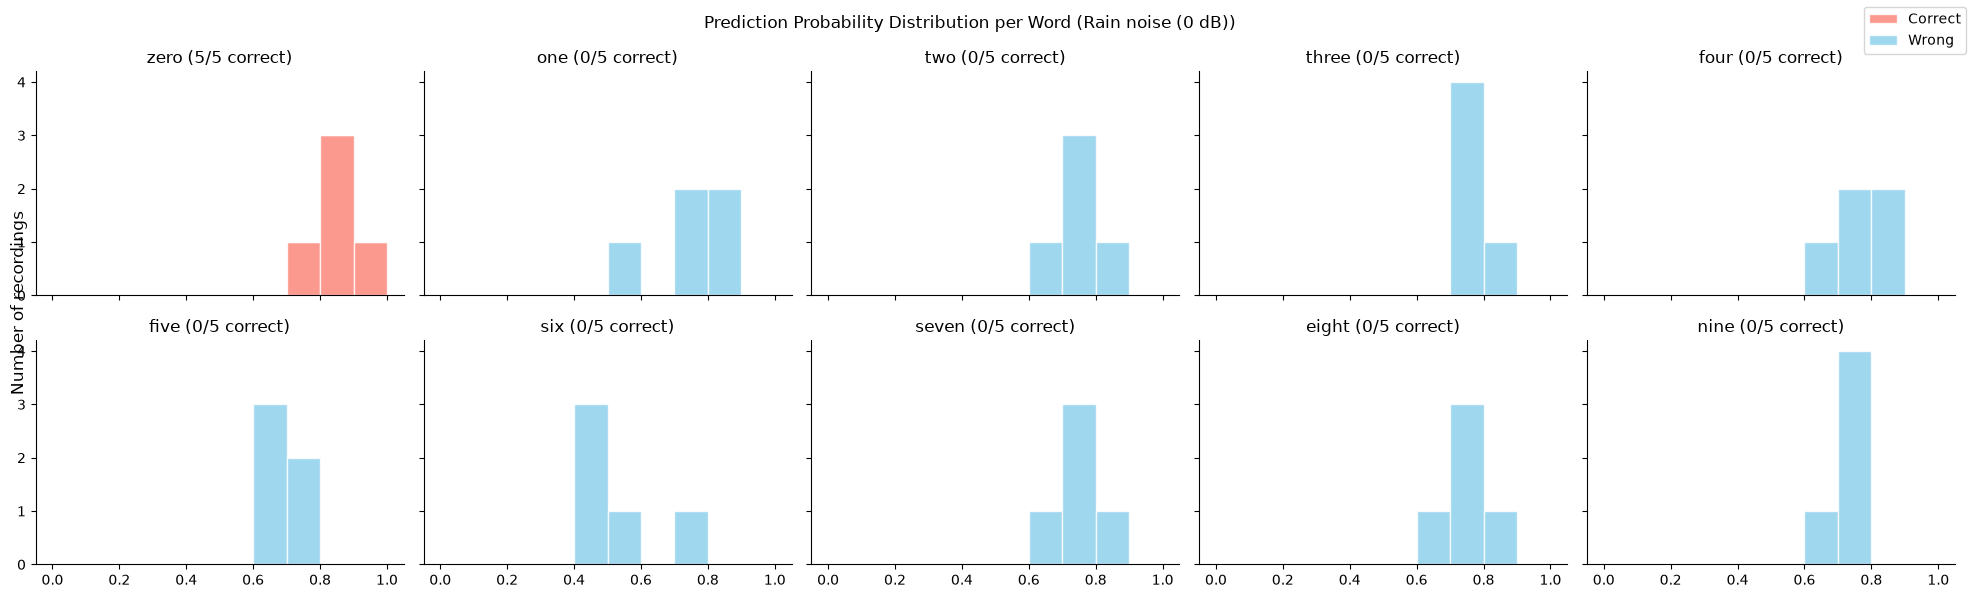

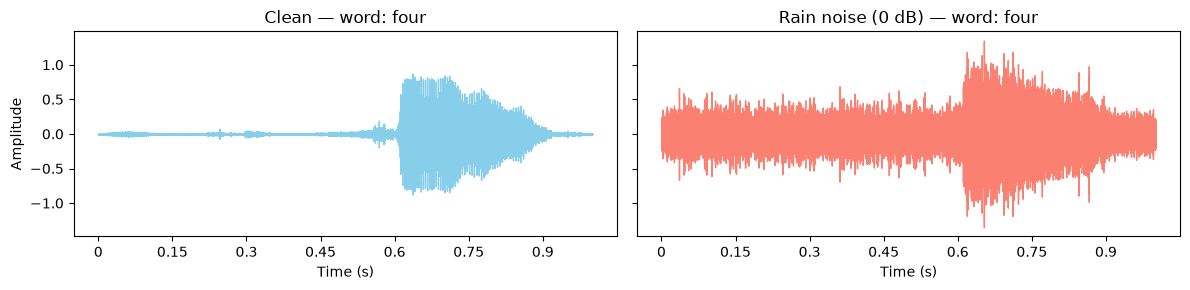

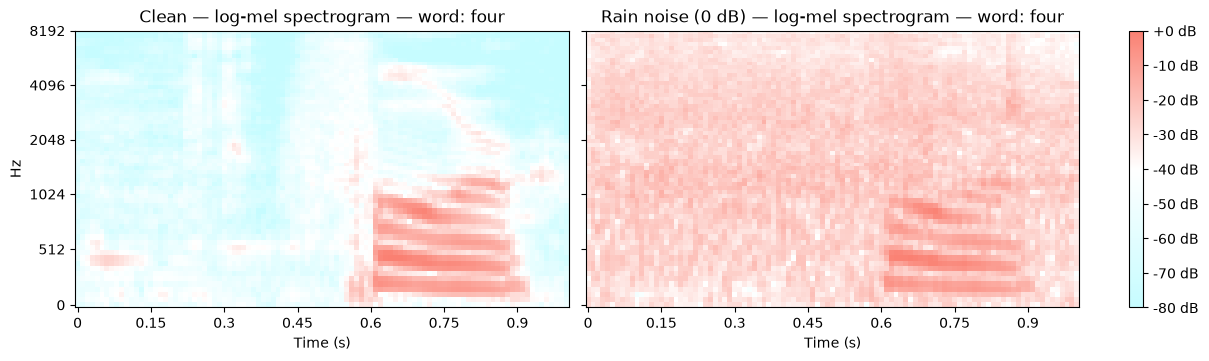

In [33]:
snr_db = 0  # signal-to-noise ratio in decibels; lower means louder noise

rain_loader = speakreg.real_noise_test_loader(audio_dataset, features, numbers, testing_speaker,
                                              rain_segments, snr_db=snr_db, mel_params=mel_params, seed=gen_seed)

noise_index += 1
test_signal, test_rate, test_word, _ = speakreg.random_test_recording(
    audio_dataset, testing_speaker, seed=gen_seed + noise_index)
condition = f"Rain noise ({snr_db} dB)"

print(f"===== Rain noise at {snr_db} dB SNR =====")
model_results[condition] = speakreg.model_output(
    model, rain_loader, numbers, static_cmap, cmap, device, condition)

speakreg.preview_real_noise(test_signal, test_rate, test_word,
                            rain_segments, snr_db, mel_params, cmap, seed=gen_seed + noise_index)

## 7. Results Comparison

Each row is one evaluation of the same trained model on the same test speaker. The columns are:
- **Accuracy, Precision, Recall:** overall test scores.
- **Average Probability:** the mean probability the model gave to the word it chose, a measure of its certainty.
- **Accuracy: word:** the fraction of that word's recordings guessed correctly.
- **Most Guessed and Most Guessed Share:** the word the model predicted most often and the share of all predictions it accounts for. A high share on one word suggests the model falls back on it when unsure.

In [34]:
comparison = speakreg.results_summary(model_results, numbers)
comparison.round(2)

,Accuracy,Precision,Recall,Average Probability,Accuracy: zero,Accuracy: one,Accuracy: two,Accuracy: three,Accuracy: four,Accuracy: five,Accuracy: six,Accuracy: seven,Accuracy: eight,Accuracy: nine,Most Guessed,Most Guessed Share
Clean speech,0.78,0.85,0.78,0.62,0.6,0.6,0.8,0.8,0.6,0.6,1.0,1.0,1.0,0.8,seven,0.20
White noise (30 dB),0.40,0.40,0.40,0.59,0.6,0.0,0.0,0.4,0.2,0.6,1.0,0.4,0.0,0.8,six,0.34
Pink noise (30 dB),0.62,0.65,0.62,0.59,1.0,0.0,0.6,0.8,0.6,0.6,1.0,0.6,0.2,0.8,five,0.18
White noise (20 dB),0.34,0.24,0.34,0.55,0.8,0.0,0.0,0.4,0.0,0.8,1.0,0.0,0.0,0.4,six,0.42
Pink noise (20 dB),0.38,0.21,0.38,0.57,1.0,0.0,0.0,0.4,0.0,0.6,1.0,0.0,0.0,0.8,zero,0.36
White noise (10 dB),0.20,0.09,0.20,0.69,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,zero,0.88
Pink noise (10 dB),0.20,0.11,0.20,0.73,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,zero,0.88
White noise (0 dB),0.10,0.01,0.10,0.85,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,zero,1.00
Pink noise (0 dB),0.10,0.01,0.10,0.93,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,zero,1.00
Rain noise (30 dB),0.46,0.51,0.46,0.59,0.8,0.0,0.0,0.6,0.2,0.6,1.0,0.4,0.2,0.8,six,0.26


The first chart tracks the overall scores across the test groups. The second shows the accuracy for each word separately, so words that hold up under noise can be told apart from those that collapse. Because every word has the same number of test recordings, macro-averaged recall is always equal to accuracy, so the two lines overlap: accuracy is drawn as the thick line and recall as the dashed line on top of it.

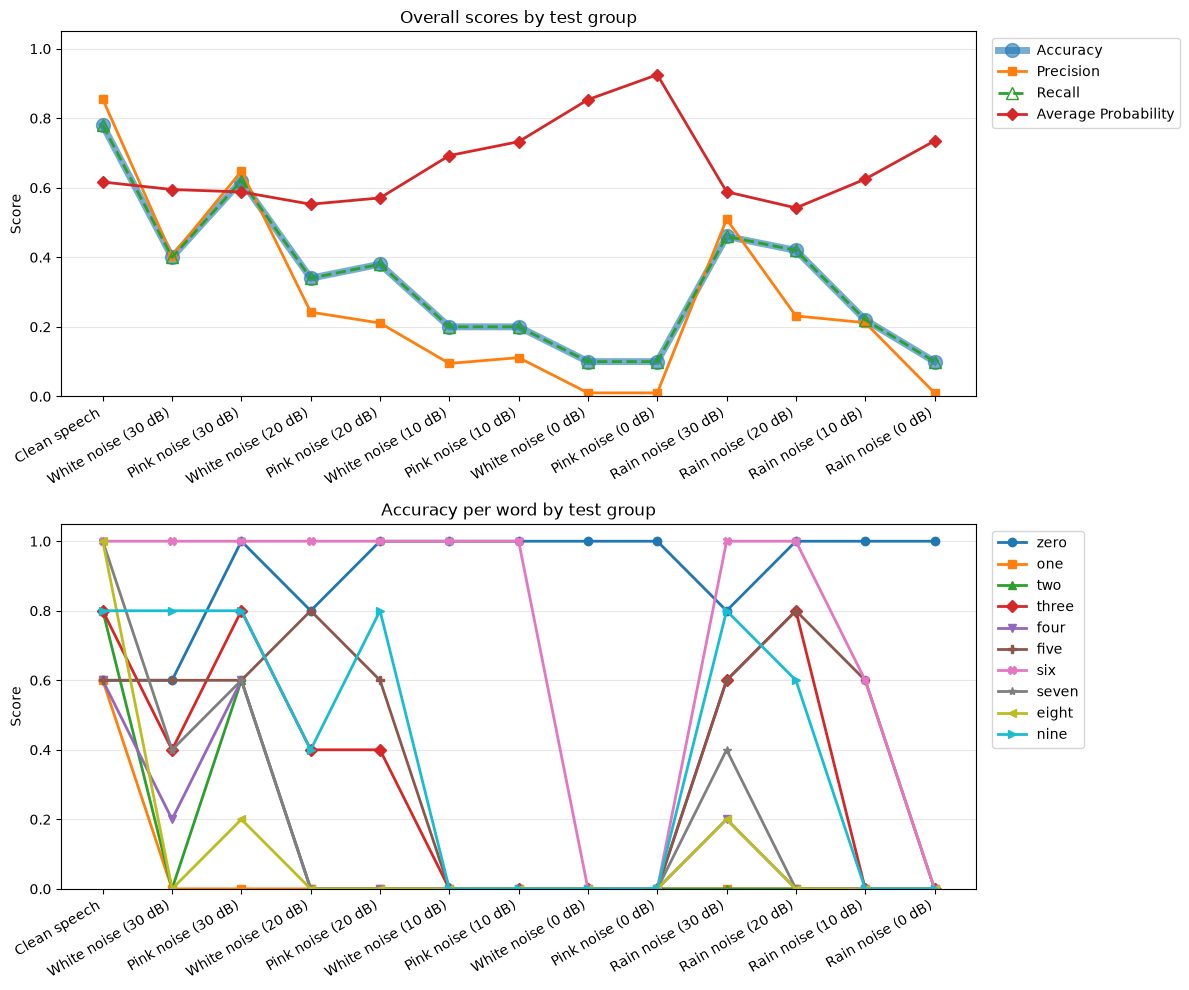

In [35]:
speakreg.plot_results_comparison(comparison, numbers)

### Most Confused Words

The table lists, for every test group, how many of the 50 test recordings were misclassified and the three most frequent confusions, written as *actual word* predict as *predicted word* (number of recordings).

In [36]:
speakreg.confusion_pairs(model_results)

,Errors,Confusion 1,Confusion 2,Confusion 3
Clean speech,11/50,four predicted as seven (2),five predicted as nine (1),five predicted as three (1)
White noise (30 dB),30/50,two predicted as six (5),one predicted as five (4),eight predicted as three (3)
Pink noise (30 dB),19/50,eight predicted as three (3),one predicted as five (3),one predicted as nine (2)
White noise (20 dB),33/50,two predicted as six (4),eight predicted as six (3),nine predicted as zero (3)
Pink noise (20 dB),31/50,seven predicted as zero (4),four predicted as zero (3),three predicted as six (3)
White noise (10 dB),40/50,eight predicted as zero (5),five predicted as zero (5),four predicted as zero (5)
Pink noise (10 dB),40/50,eight predicted as zero (5),four predicted as zero (5),nine predicted as zero (5)
White noise (0 dB),45/50,eight predicted as zero (5),five predicted as zero (5),four predicted as zero (5)
Pink noise (0 dB),45/50,eight predicted as zero (5),five predicted as zero (5),four predicted as zero (5)
Rain noise (30 dB),27/50,eight predicted as three (3),one predicted as five (3),two predicted as six (3)
